# Analytical Dataset Construction — Online Retail II (Phase A-3-5)
**Customer-Level Feature Engineering, Bidirectional Credit Netting (`NettedHotFixFlag`), Marketing Attribution Proxies, and Forensic Governance**

**Upstream inputs from Phase A-3-4 (Route B selected):**
1. `../A-3-4_DataCleaning/outputs/transacciones_procesadas.csv` — `1,027,016` deduplicated, validated transaction lines (`1,007,913` `Purchase` lines + `19,103` `Credit` lines).
2. `../A-3-4_DataCleaning/outputs/auditoria_conciliacion_abonos.csv` — `19,103` rows × `25` columns with full bidirectional credit traceability (`Status`, `LinkedInvoice`, `LinkedInvoiceClose`, `ForwardInvoice`, `ForwardGapHours`, `TemporalArchetype`, and `NettedHotFixFlag`).

**Outputs generated in `outputs/` and `figures/`:**
- `outputs/clientes_rfm.csv` (`5,878` customers: core `CustomerID, Recency, Frequency, Monetary` + forensic hot-fix-netted, merchandise-pure, basket-diversity, and marketing-proxy features)
- `outputs/clientes_clasificacion.csv` (`2,724` customers: core `CustomerID, RecencyDays, TotalOrders, TotalSpent, Repurchase90Days` + pre-cutoff forensic and marketing-proxy features with zero data leakage)
- `outputs/resultados_actividad3.json` (complete audit ledger for technical reporting and Phase A-3-6 handoff)
- High-resolution diagnostic figures in `figures/` (`fig1_hotfix_and_nonmerch_rfm.png`, `fig2_classification_windows_lifo_leakage.png`, `fig3_marketing_proxies_and_forensic_governance.png`)

---
## 0. Source Control, Bidirectional Credit Linkage & Forensic Governance Rules
Before aggregating to the customer level, we verify the integrity of the upstream Route B ledger (`1,027,016` rows), join the bidirectional credit reconciliation audit (`19,103` rows), and enforce the **6 Forensic Governance Rules** established in Phases A-3-3 and A-3-4:
1. **Hot-Fix Re-Invoicing Netting (`NettedHotFixFlag == True`):** Identify the `1,499` credit lines (`-£172,308.44` across `393` customers, `1,181` re-billed in $\le 60$ min) where an invoice was cancelled and immediately re-issued within `< 24` hours (`ForwardInvoice`), preventing artificial inflation of order `Frequency` and customer return rates (`TrueReturnRate` vs. `RawCreditRate`).
2. **Deterministic Disambiguation of Repeat-Buyer Credits (`5,393` `Ambiguous` lines):** Combine Stage-1 unique matches (`9,827` lines) with **Exact Lot-Size Matching (`1,794` lines)** and **LIFO (`3,599` lines)** to resolve **100% (`15,220` lines, `82.76%` of identified credits)** to their originating purchase timestamp (`ResolvedInvoiceDate`), plus track the `1,474` left-censored pre-Dec 2009 orphan lines (`61` credit-only accounts in Route B vs. `64` in the Common Base).
3. **Multi-Country Customer Canonicalization (`13` B2B Accounts):** Group strictly by `CustomerID` (never by `['CustomerID', 'Country']`) and assign each customer's modal `Country` so the `13` multi-country B2B customers (including `12745` across `United Kingdom` and `EIRE`) are never duplicated.
4. **Non-Merchandise & Bad-Debt Separation (`5,761` lines in Route B):** Isolate the `21` non-merchandise codes (`POST`, `DOT`, `M`, `D`, `C2`, `AMAZONFEE`, `BANK CHARGES`, `CRUK`, `PADS`, `ADJUST`, `ADJUST2`, `TEST001`, `TEST002`, and positive bad-debt `B` in `A563185` for `+£11,062.06`) from the `1,021,255` pure retail merchandise lines (`IsMerchandise == 1`).
5. **Case-Insensitive SKU Normalization (`4,932` $ightarrow$ `4,760` SKUs) & Intra-Invoice Split Line Collapse (`11,109` raw / `10,291` identified pairs):** Normalize `StockCode_Norm = StockCode.str.strip().str.upper()` and collapse intra-invoice duplicate `(Invoice, StockCode_Norm)` lines before measuring basket size and product diversity (`UniqueSKUs`).
6. **Marketing Attribution Proxy Engineering (0 UTMs):** Construct customer-level `CohortMonth`, `TenureDays`, `IsUK`, `DOTCOM_OrderFlag`, and `DISCOUNT_UserFlag` (`55` wholesale accounts).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams.update({'figure.dpi': 140, 'savefig.dpi': 200, 'font.size': 9.5, 'axes.titlesize': 10.5, 'axes.labelsize': 9.5})

SRC = Path('../A-3-4_DataCleaning/outputs/transacciones_procesadas.csv')
AUD_SRC = Path('../A-3-4_DataCleaning/outputs/auditoria_conciliacion_abonos.csv')
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
R = {}

df = pd.read_csv(SRC, dtype={'Invoice': str, 'StockCode': str}, parse_dates=['InvoiceDate'])
df = df.rename(columns={
    'FilaOrigen': 'SourceRow', 'Cantidad': 'Quantity', 'Precio': 'Price',
    'Pais': 'Country', 'ImporteLinea': 'LineAmount', 'Fecha': 'Date',
    'TipoMovimiento': 'MovementType'
})
df['MovementType'] = df['MovementType'].replace({'Compra': 'Purchase', 'Abono': 'Credit'})

aud = pd.read_csv(AUD_SRC, dtype={'Invoice': str, 'StockCode': str, 'LinkedInvoice': str, 'ForwardInvoice': str},
                  parse_dates=['InvoiceDate', 'LinkedInvoiceClose', 'ForwardInvoiceDate', 'FirstPurchaseDate', 'LastPurchaseDate'])

assert len(df) == 1_027_016 and df['SourceRow'].is_unique
assert len(aud) == 19_103
assert set(df['MovementType']) == {'Purchase', 'Credit'}
assert (df.loc[df['MovementType'] == 'Purchase', 'Quantity'] > 0).all()
assert (df.loc[df['MovementType'] == 'Credit', 'Quantity'] < 0).all()
assert (df['Price'] > 0).all()
assert np.isclose(df['LineAmount'], df['Quantity'] * df['Price']).all()

# Verify 1-to-1 alignment between Credit rows in df and auditoria_conciliacion_abonos.csv
cred_mask = df['MovementType'] == 'Credit'
assert (df.loc[cred_mask, 'SourceRow'].values == aud['SourceRow'].values).all()

for col in ['Status', 'Reason', 'NCandidates', 'LinkedInvoice', 'LinkedInvoiceClose', 'LinkedInvoiceUnits',
            'PartialReturn', 'FirstPurchaseDate', 'LastPurchaseDate', 'TotalPurchaseLines',
            'ForwardInvoice', 'ForwardInvoiceDate', 'ForwardInvoiceUnits', 'ForwardInvoicePrice',
            'ForwardGapHours', 'TemporalArchetype', 'NettedHotFixFlag']:
    df.loc[cred_mask, col] = aud[col].values

df['NettedHotFixFlag'] = df['NettedHotFixFlag'].where(df['NettedHotFixFlag'].notna(), False).astype(bool)

# Forensic Governance Rules: StockCode normalization & Non-Merchandise separation
NON_MERCH_CODES = {'POST', 'DOT', 'M', 'C2', 'D', 'BANK CHARGES', 'AMAZONFEE', 'CRUK', 'PADS',
                   'ADJUST', 'ADJUST2', 'B', 'S', 'TEST001', 'TEST002', 'SP1002',
                   'GIFT_0001_10', 'GIFT_0001_20', 'GIFT_0001_30', 'GIFT_0001_40', 'GIFT_0001_50'}
df['StockCode_Norm'] = df['StockCode'].astype(str).str.strip().str.upper()
df['IsMerchandise'] = (~df['StockCode_Norm'].isin(NON_MERCH_CODES) & ~df['Invoice'].str.upper().str.startswith('A')).astype(int)

dot_invoices = set(df.loc[df['StockCode_Norm'] == 'DOT', 'Invoice'].unique())
df['DOTCOM_OrderFlag'] = df['Invoice'].isin(dot_invoices).astype(int)

with_id = df['CustomerID'].notna()
summary_0 = pd.DataFrame([
    ('Total rows (Route B)', len(df), df['Invoice'].nunique(), df['LineAmount'].sum()),
    ('  Purchases (Quantity > 0)', int((df['MovementType'] == 'Purchase').sum()), df.loc[df['MovementType'] == 'Purchase', 'Invoice'].nunique(), df.loc[df['MovementType'] == 'Purchase', 'LineAmount'].sum()),
    ('  C credits (Quantity < 0)', int((df['MovementType'] == 'Credit').sum()), df.loc[df['MovementType'] == 'Credit', 'Invoice'].nunique(), df.loc[df['MovementType'] == 'Credit', 'LineAmount'].sum()),
    ('  Pure Merchandise (IsMerchandise == 1)', int((df['IsMerchandise'] == 1).sum()), df.loc[df['IsMerchandise'] == 1, 'Invoice'].nunique(), df.loc[df['IsMerchandise'] == 1, 'LineAmount'].sum()),
    ('  Non-Merchandise / Admin (IsMerchandise == 0)', int((df['IsMerchandise'] == 0).sum()), df.loc[df['IsMerchandise'] == 0, 'Invoice'].nunique(), df.loc[df['IsMerchandise'] == 0, 'LineAmount'].sum()),
    ('Rows without CustomerID (Anonymous Repo)', int((~with_id).sum()), df.loc[~with_id, 'Invoice'].nunique(), df.loc[~with_id, 'LineAmount'].sum()),
    ('Rows with CustomerID (CRM Repo)', int(with_id.sum()), df.loc[with_id, 'Invoice'].nunique(), df.loc[with_id, 'LineAmount'].sum()),
    ('  with CustomerID – Purchases', int((with_id & (df['MovementType'] == 'Purchase')).sum()), df.loc[with_id & (df['MovementType'] == 'Purchase'), 'Invoice'].nunique(), df.loc[with_id & (df['MovementType'] == 'Purchase'), 'LineAmount'].sum()),
    ('  with CustomerID – C credits', int((with_id & (df['MovementType'] == 'Credit')).sum()), df.loc[with_id & (df['MovementType'] == 'Credit'), 'Invoice'].nunique(), df.loc[with_id & (df['MovementType'] == 'Credit'), 'LineAmount'].sum()),
], columns=['Subset', 'Lines', 'Invoices', 'Amount (£)'])
display(summary_0)

,Subset,Lines,Invoices,Amount (£)
0,Total rows (Route B),1027016,48368,"19,013,836.27"
1,Purchases (Quantity > 0),1007913,40077,"20,476,260.45"
2,C credits (Quantity < 0),19103,8291,"-1,462,424.18"
3,Pure Merchandise (IsMerchandise == 1),1021255,46922,"18,927,480.47"
4,Non-Merchandise / Admin (IsMerchandise == 0),5761,5432,"86,355.80"
5,Rows without CustomerID (Anonymous Repo),229201,3498,"2,723,844.98"
6,Rows with CustomerID (CRM Repo),797815,44870,"16,289,991.29"
7,with CustomerID – Purchases,779425,36969,"17,374,804.27"
8,with CustomerID – C credits,18390,7901,"-1,084,812.98"


In [2]:
ident = df[with_id].copy()
ident['CustomerID'] = ident['CustomerID'].astype(int)

# Deterministic LIFO + Exact Lot-Size Disambiguation for the 5,393 Ambiguous Credits
cred_all_id = ident[ident['MovementType'] == 'Credit'].copy()
ambig_keys = set(cred_all_id.loc[cred_all_id['Status'] == 'Ambiguous', ['CustomerID', 'StockCode', 'Price']].itertuples(index=False, name=None))
purch_all_id = ident[ident['MovementType'] == 'Purchase'].copy()
purch_ambig = purch_all_id[purch_all_id.set_index(['CustomerID', 'StockCode', 'Price']).index.isin(ambig_keys)]
p_inv_lookup = {}
p_inv_df = purch_ambig.groupby(['CustomerID', 'StockCode', 'Price', 'Invoice'], as_index=False).agg(
    InvClose=('InvoiceDate', 'max'),
    InvUnits=('Quantity', 'sum')
).sort_values('InvClose')
for (cid, sc, pr), grp in p_inv_df.groupby(['CustomerID', 'StockCode', 'Price']):
    p_inv_lookup[(cid, sc, pr)] = list(zip(grp['InvClose'], grp['Invoice'], grp['InvUnits']))

res_inv = cred_all_id['LinkedInvoice'].copy()
res_date = cred_all_id['LinkedInvoiceClose'].copy()
res_method = pd.Series(np.where(cred_all_id['Status'] == 'Reconciled', '1. Stage-1 Unique Match', '3. Unreconciled (See Archetype)'), index=cred_all_id.index)

for idx_c, r_c in cred_all_id[cred_all_id['Status'] == 'Ambiguous'].iterrows():
    key = (int(r_c['CustomerID']), r_c['StockCode'], r_c['Price'])
    c_dt = r_c['InvoiceDate']
    ret_u = abs(int(r_c['Quantity']))
    cands = [c for c in p_inv_lookup.get(key, []) if c[0] < c_dt and c[2] >= ret_u]
    exact = [c for c in cands if c[2] == ret_u]
    if exact:
        chosen = exact[-1]
        res_inv.loc[idx_c] = chosen[1]; res_date.loc[idx_c] = chosen[0]; res_method.loc[idx_c] = '2a. Exact Lot-Size + LIFO'
    elif cands:
        chosen = cands[-1]
        res_inv.loc[idx_c] = chosen[1]; res_date.loc[idx_c] = chosen[0]; res_method.loc[idx_c] = '2b. LIFO (Sufficient Balance)'
    else:
        prior = [c for c in p_inv_lookup.get(key, []) if c[0] < c_dt]
        chosen = prior[-1]
        res_inv.loc[idx_c] = chosen[1]; res_date.loc[idx_c] = chosen[0]; res_method.loc[idx_c] = '2b. LIFO (Sufficient Balance)'

ident.loc[ident['MovementType'] == 'Credit', 'ResolvedInvoice'] = res_inv
ident.loc[ident['MovementType'] == 'Credit', 'ResolvedInvoiceDate'] = pd.to_datetime(res_date)
ident.loc[ident['MovementType'] == 'Credit', 'ResolutionMethod'] = res_method

cust_all = set(ident['CustomerID'].unique())
cust_purch = set(ident.loc[ident['MovementType'] == 'Purchase', 'CustomerID'].unique())
cust_only_cred = sorted(cust_all - cust_purch)
only_cred_df = ident[ident['CustomerID'].isin(cust_only_cred)]

# Multi-country customers check
cust_ctry_n = ident.groupby('CustomerID')['Country'].nunique()
multi_ctry_ids = sorted(cust_ctry_n[cust_ctry_n > 1].index.tolist())

# Intra-invoice split SKU pairs check
raw_split_pairs = int((df.groupby(['Invoice', 'StockCode']).size() > 1).sum())
norm_split_pairs = int((df.groupby(['Invoice', 'StockCode_Norm']).size() > 1).sum())
ident_split_pairs = int((ident.groupby(['Invoice', 'StockCode_Norm']).size() > 1).sum())

print(f'Date range: {df.InvoiceDate.min()} -> {df.InvoiceDate.max()}')
print(f'Distinct CustomerID in Route B: {len(cust_all):,} (note: Common Base before Price > 0 filter had 5,942 customers; 3 had only Price == 0 rows)')
print(f'  with >= 1 valid purchase (RFM universe): {len(cust_purch):,}')
print(f'  with C credits ONLY in Route B (excluded from RFM, 100% Left-Censored Orphans): {len(cust_only_cred)} ({len(only_cred_df)} lines, {only_cred_df.Invoice.nunique()} invoices, £{only_cred_df.LineAmount.sum():,.2f})')
print(f'Multi-country CustomerIDs ({len(multi_ctry_ids)}): {multi_ctry_ids} -> grouping by (CustomerID, Country) would create {len(ident.groupby(["CustomerID", "Country"])) - len(cust_all)} duplicate customer rows!')
print(f'Case-normalized SKUs: {df.StockCode.nunique():,} raw -> {df.StockCode_Norm.nunique():,} canonical ({df.StockCode.nunique() - df.StockCode_Norm.nunique()} case-split SKUs collapsed)')
print(f'Intra-invoice split (Invoice, StockCode) pairs: {raw_split_pairs:,} raw ({norm_split_pairs:,} normalized; {ident_split_pairs:,} in identified CRM rows)')

# Bidirectional Credit Taxonomy & LIFO Resolution Summary Table on Identified Credits (18,390 lines)
cred_id_full = ident[ident['MovementType'] == 'Credit']
arch_tbl = cred_id_full.groupby('TemporalArchetype').agg(
    CreditLines=('SourceRow', 'size'),
    DistinctInvoices=('Invoice', 'nunique'),
    DistinctCustomers=('CustomerID', 'nunique'),
    CreditAmount_GBP=('LineAmount', 'sum'),
    HotFix_Lines=('NettedHotFixFlag', lambda s: int(s.sum()))
)
arch_tbl['% of Identified Credits'] = (100 * arch_tbl['CreditLines'] / len(cred_id_full)).round(2)
print('\nBidirectional Credit Taxonomy across the 18,390 Identified Credit Lines (16,916 paired + 1,474 orphan):')
display(arch_tbl)

res_tbl = cred_id_full.groupby('ResolutionMethod').agg(
    CreditLines=('SourceRow', 'size'),
    CreditAmount_GBP=('LineAmount', 'sum')
)
res_tbl['% of Identified Credits'] = (100 * res_tbl['CreditLines'] / len(cred_id_full)).round(2)
print('Backward Purchase Disambiguation (Stage 1 + Exact Lot Size + LIFO):')
display(res_tbl)

R['fuente'] = dict(
    filas=len(df), compras=int((df['MovementType'] == 'Purchase').sum()),
    abonos=int((df['MovementType'] == 'Credit').sum()),
    sin_id_filas=int((~with_id).sum()), sin_id_imp=round(float(df.loc[~with_id, 'LineAmount'].sum()), 2),
    con_id_filas=int(with_id.sum()), con_id_imp=round(float(df.loc[with_id, 'LineAmount'].sum()), 2),
    clientes_totales=len(cust_all), clientes_con_compra=len(cust_purch),
    clientes_solo_abono=len(cust_only_cred), solo_abono_lineas=len(only_cred_df),
    solo_abono_facturas=int(only_cred_df['Invoice'].nunique()),
    solo_abono_imp=round(float(only_cred_df['LineAmount'].sum()), 2),
    solo_abono_ids=cust_only_cred[:10],
    f_min=str(df['InvoiceDate'].min()), f_max=str(df['InvoiceDate'].max()),
    skus_raw=int(df['StockCode'].nunique()), skus_norm=int(df['StockCode_Norm'].nunique()),
    split_pairs_raw=raw_split_pairs, split_pairs_norm=norm_split_pairs, split_pairs_ident=ident_split_pairs,
    multi_country_clientes=len(multi_ctry_ids), multi_country_ids=multi_ctry_ids,
    no_merch_lineas_total=int((df['IsMerchandise'] == 0).sum()),
    no_merch_lineas_ident=int((ident['IsMerchandise'] == 0).sum()),
    hotfix_lineas_ident=int(cred_id_full['NettedHotFixFlag'].sum()),
    hotfix_imp_ident=round(float(cred_id_full.loc[cred_id_full['NettedHotFixFlag'], 'LineAmount'].sum()), 2),
    hotfix_clientes_ident=int(cred_id_full.loc[cred_id_full['NettedHotFixFlag'], 'CustomerID'].nunique()),
    lifo_resueltos_total=int(cred_id_full['ResolvedInvoice'].notna().sum()),
    lifo_lote_exacto=int((cred_id_full['ResolutionMethod'] == '2a. Exact Lot-Size + LIFO').sum())
)

Date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00
Distinct CustomerID in Route B: 5,939 (note: Common Base before Price > 0 filter had 5,942 customers; 3 had only Price == 0 rows)
  with >= 1 valid purchase (RFM universe): 5,878
  with C credits ONLY in Route B (excluded from RFM, 100% Left-Censored Orphans): 61 (128 lines, 65 invoices, £-61,049.67)
Multi-country CustomerIDs (13): [12370, 12394, 12413, 12417, 12422, 12423, 12429, 12431, 12449, 12455, 12457, 12652, 12745] -> grouping by (CustomerID, Country) would create 13 duplicate customer rows!
Case-normalized SKUs: 4,932 raw -> 4,760 canonical (172 case-split SKUs collapsed)
Intra-invoice split (Invoice, StockCode) pairs: 11,109 raw (11,112 normalized; 10,291 in identified CRM rows)

Bidirectional Credit Taxonomy across the 18,390 Identified Credit Lines (16,916 paired + 1,474 orphan):
Backward Purchase Disambiguation (Stage 1 + Exact Lot Size + LIFO):


,CreditLines,DistinctInvoices,DistinctCustomers,CreditAmount_GBP,HotFix_Lines,% of Identified Credits
TemporalArchetype,,,,,,
1. Pure Post-Purchase Return (All Purchases < C),9765,4843,2161,"-528,122.69",0,53.10
2. Hot-Fix Re-Invoicing (< 24h Forward Match),1499,767,393,"-172,308.44",1499,8.15
3. Short-Term Re-Invoicing (1-7d Forward Match),640,369,191,"-23,601.72",0,3.48
4. Subsequent Cycle Repurchase (> 7d Forward Match),5012,2893,1042,"-160,331.19",0,27.25
5. Left-Censored Orphan (Pre-Dec 2009 / Counter),1474,986,670,"-200,448.94",0,8.02


,CreditLines,CreditAmount_GBP,% of Identified Credits
ResolutionMethod,,,
1. Stage-1 Unique Match,9827,"-588,174.90",53.44
2a. Exact Lot-Size + LIFO,1794,"-91,441.21",9.76
2b. LIFO (Sufficient Balance),3599,"-41,282.29",19.57
3. Unreconciled (See Archetype),3170,"-363,914.58",17.24


---
## 1. RFM Dataset (`outputs/clientes_rfm.csv`) — Core Metrics, Hot-Fix Netting & Marketing Proxies

### Operational Definitions & Forensic Governance
- **Universe:** `5,878` unique `CustomerID`s with at least one valid `Purchase` in the full period (`2009-12-01` – `2011-12-09`). The `61` accounts in Route B that only have `Credit` lines (`128` lines, `-£61,049.67`, `100%` archetype `5. Left-Censored Orphan`) have no positive purchase timestamp to anchor `Recency` or `Frequency` and are documented separately.
- **Reference Date (`REF`):** `2011-12-10 00:00:00` (the day after the last timestamp `2011-12-09 12:50:00`), guaranteeing `Recency >= 0` (`min = 0` days for purchases on `2011-12-09`, `max = 738` days for `2009-12-01`).
- **Core Rubric Features:**
  - `Recency`: `(REF - max(InvoiceDate_Purchase)).days` (`Credit` notes do not update recency).
  - `Frequency`: `nunique(Invoice_Purchase)` (raw count of distinct positive purchase invoices).
  - `Monetary`: `sum(LineAmount_Purchase) + sum(LineAmount_Credit)` (net spend under Route B).
- **Forensic & Hot-Fix Netted Features (New in Phase A-3-5):**
  - `Frequency_NetHotFix`: Net distinct purchase orders after discounting replacement `ForwardInvoice`s generated within `< 24` hours of a linked cancellation (`NettedHotFixFlag == True` with prior purchase), removing **`601` double-counted re-invoicing orders across `309` customers** (or `738` orders across `384` customers if discounting all `< 24h` forward matches including out-of-order/orphan bills).
  - `Monetary_Merchandise`: Net spend restricted to pure retail merchandise (`IsMerchandise == 1`), removing the distortion of `3,652` identified non-merchandise lines (`M`, `POST`, `D`, `DOT`, `C2`, `CRUK`, `ADJUST`).
  - `RawCreditRate` vs. `TrueReturnRate`: `RawCreditRate = -CreditAmount / PurchaseAmount` vs. `TrueReturnRate = -(CreditAmount - HotFix_CreditAmount) / PurchaseAmount`. Netting out the `1,499` hot-fix lines (`-£172,308.44`) reduces the return rate of `393` customers and **restores `63` loyal customers from a false positive return rate to `0.00%`**.
  - `UniqueSKUs` & `PurchaseLines_Collapsed`: Distinct normalized merchandise SKUs (`StockCode_Norm`) and intra-invoice collapsed purchase lines (removing `10,560` split-scan excess lines across `1,529` customers).
- **Marketing Attribution Proxy Features (0 UTMs):**
  - `CohortMonth` (`YYYY-MM` of first positive purchase) & `TenureDays` (`(REF - min(InvoiceDate_Purchase)).days`).
  - `Country` (canonical modal country per `CustomerID`, resolving the `13` multi-country B2B accounts) & `IsUK` (`1` = domestic UK [`5,350` customers, `91.02%`], `0` = international export [`528` customers, `8.98%`]).
  - `DOTCOM_OrderFlag` (`StockCode == 'DOT'`) & `DISCOUNT_UserFlag` (`55` wholesale accounts with manual discount lines `StockCode == 'D'`).

In [3]:
REF = pd.Timestamp('2011-12-10 00:00:00')
purch = ident[ident['MovementType'] == 'Purchase'].copy()
cred  = ident[ident['MovementType'] == 'Credit'].copy()

# Core RFM aggregation strictly by CustomerID
rfm = purch.groupby('CustomerID').agg(
    LastPurchase=('InvoiceDate', 'max'),
    FirstPurchase=('InvoiceDate', 'min'),
    Frequency=('Invoice', 'nunique'),
    PurchaseAmount=('LineAmount', 'sum'),
    PurchaseLines=('LineAmount', 'count'),
    PurchaseUnits=('Quantity', 'sum'),
)
rfm['Recency'] = (REF - rfm['LastPurchase']).dt.days

cred_by_cust = cred.groupby('CustomerID').agg(
    CreditAmount=('LineAmount', 'sum'),
    CreditLines=('LineAmount', 'count'),
    CreditInvoices=('Invoice', 'nunique'),
    CreditUnits=('Quantity', 'sum'),
)
rfm = rfm.join(cred_by_cust, how='left')
for c in ['CreditAmount', 'CreditLines', 'CreditInvoices', 'CreditUnits']:
    rfm[c] = rfm[c].fillna(0)
rfm['CreditLines'] = rfm['CreditLines'].astype(int)
rfm['CreditInvoices'] = rfm['CreditInvoices'].astype(int)
rfm['CreditUnits'] = rfm['CreditUnits'].astype(int)
rfm['Monetary'] = (rfm['PurchaseAmount'] + rfm['CreditAmount']).round(2)

# 1. Hot-Fix Netting (NettedHotFixFlag == True)
hf_cred = cred[cred['NettedHotFixFlag'] == True]
hf_with_prior = hf_cred[hf_cred['Status'].isin(['Reconciled', 'Ambiguous'])]

hf_amt_s = hf_cred.groupby('CustomerID')['LineAmount'].sum().reindex(rfm.index, fill_value=0.0)
hf_fwd_prior_s = hf_with_prior.groupby('CustomerID')['ForwardInvoice'].nunique().reindex(rfm.index, fill_value=0)
hf_fwd_all_s = hf_cred.groupby('CustomerID')['ForwardInvoice'].nunique().reindex(rfm.index, fill_value=0)

rfm['Frequency_NetHotFix'] = np.maximum(1, rfm['Frequency'] - hf_fwd_prior_s).astype(int)
rfm['Frequency_NetAllHotFix'] = np.maximum(1, rfm['Frequency'] - hf_fwd_all_s).astype(int)
rfm['HotFix_CreditAmount'] = hf_amt_s.round(2)
rfm['TrueReturnAmount'] = (rfm['CreditAmount'] - rfm['HotFix_CreditAmount']).round(2)
rfm['RawCreditRate'] = (-rfm['CreditAmount'] / rfm['PurchaseAmount']).round(6)
rfm['TrueReturnRate'] = (-rfm['TrueReturnAmount'] / rfm['PurchaseAmount']).round(6)
rfm['HotFix_Flag'] = rfm.index.isin(set(hf_cred['CustomerID'])).astype(int)

# 2. Pure Merchandise Monetary (IsMerchandise == 1)
merch_ident = ident[ident['IsMerchandise'] == 1]
rfm['Monetary_Merchandise'] = merch_ident.groupby('CustomerID')['LineAmount'].sum().reindex(rfm.index, fill_value=0.0).round(2)
rfm['NonMerch_NetAmount'] = (rfm['Monetary'] - rfm['Monetary_Merchandise']).round(2)

# 3. Normalized Product Diversity (UniqueSKUs) & Intra-Invoice Split Line Collapse
merch_purch = purch[purch['IsMerchandise'] == 1]
rfm['UniqueSKUs'] = merch_purch.groupby('CustomerID')['StockCode_Norm'].nunique().reindex(rfm.index, fill_value=0).astype(int)
collapsed_p_lines = purch.groupby(['CustomerID', 'Invoice', 'StockCode_Norm']).size().groupby('CustomerID').size()
rfm['PurchaseLines_Collapsed'] = collapsed_p_lines.reindex(rfm.index, fill_value=0).astype(int)
rfm['SplitLine_Excess'] = (rfm['PurchaseLines'] - rfm['PurchaseLines_Collapsed']).astype(int)

# 4. Marketing Attribution Proxies & Canonical Country
rfm['CohortMonth'] = rfm['FirstPurchase'].dt.to_period('M').astype(str)
rfm['TenureDays'] = (REF - rfm['FirstPurchase']).dt.days.astype(int)

canonical_ctry = ident.sort_values('InvoiceDate').groupby('CustomerID')['Country'].agg(
    lambda s: s.mode().iloc[0] if len(s.mode()) > 0 else s.iloc[-1]
)
rfm['Country'] = canonical_ctry.reindex(rfm.index)
rfm['IsUK'] = (rfm['Country'] == 'United Kingdom').astype(int)
rfm['DOTCOM_OrderFlag'] = rfm.index.isin(set(ident.loc[ident['DOTCOM_OrderFlag'] == 1, 'CustomerID'])).astype(int)
rfm['DISCOUNT_UserFlag'] = rfm.index.isin(set(ident.loc[ident['StockCode_Norm'] == 'D', 'CustomerID'])).astype(int)

# Export enriched clientes_rfm.csv (core 4 columns first + 13 forensic/proxy features)
RFM_EXPORT_COLS = [
    'CustomerID', 'Recency', 'Frequency', 'Monetary',
    'Frequency_NetHotFix', 'Monetary_Merchandise', 'RawCreditRate', 'TrueReturnRate',
    'HotFix_Flag', 'UniqueSKUs', 'PurchaseLines_Collapsed',
    'CohortMonth', 'TenureDays', 'Country', 'IsUK', 'DOTCOM_OrderFlag', 'DISCOUNT_UserFlag'
]
rfm_out = rfm.reset_index()[RFM_EXPORT_COLS].sort_values('CustomerID')
rfm_out.to_csv(OUT / 'clientes_rfm.csv', index=False)
print('Exported outputs/clientes_rfm.csv:', rfm_out.shape)
display(rfm_out.head(10))

Exported outputs/clientes_rfm.csv: (5878, 17)


,CustomerID,Recency,Frequency,Monetary,Frequency_NetHotFix,Monetary_Merchandise,RawCreditRate,TrueReturnRate,HotFix_Flag,UniqueSKUs,PurchaseLines_Collapsed,CohortMonth,TenureDays,Country,IsUK,DOTCOM_OrderFlag,DISCOUNT_UserFlag
0,12346,325,12,-51.74,12,169.36,1.00,1.00,0,25,34,2009-12,725,United Kingdom,1,0,1
1,12347,2,8,"4,921.53",8,"4,921.53",-0.00,-0.00,0,126,222,2010-10,404,Iceland,0,0,0
2,12348,75,5,"2,019.40",5,"1,658.40",-0.00,-0.00,0,24,47,2010-09,438,Finland,0,0,0
3,12349,18,4,"4,404.54",4,"3,654.54",0.01,0.01,0,137,175,2010-04,589,Italy,0,0,0
4,12350,310,1,334.40,1,294.40,-0.00,-0.00,0,16,17,2011-02,310,Norway,0,0,0
5,12351,375,1,300.93,1,300.93,-0.00,-0.00,0,21,21,2010-11,375,Unspecified,0,0,0
6,12352,36,10,"1,889.21",9,"1,609.21",0.34,-0.00,1,68,101,2010-11,392,Norway,0,0,0
7,12353,204,2,406.76,2,406.76,-0.00,-0.00,0,23,24,2010-10,408,Bahrain,0,0,0
8,12354,232,1,"1,079.40",1,"1,079.40",-0.00,-0.00,0,58,58,2011-04,232,Spain,0,0,0
9,12355,214,2,947.61,2,947.61,-0.00,-0.00,0,35,35,2010-05,567,Bahrain,0,0,0


In [4]:
# Comprehensive Statistical Summary: Core RFM vs. Forensic Netted & Proxy Features
stats_cols = ['Recency', 'Frequency', 'Frequency_NetHotFix', 'Monetary', 'Monetary_Merchandise',
              'RawCreditRate', 'TrueReturnRate', 'UniqueSKUs', 'PurchaseLines_Collapsed', 'TenureDays']
desc = rfm[stats_cols].describe(percentiles=[.01, .05, .25, .5, .75, .9, .95, .99]).T
desc['IQR'] = desc['75%'] - desc['25%']
desc['skew'] = rfm[stats_cols].skew()
display(desc[['count', 'mean', 'std', 'min', '5%', '25%', '50%', '75%', '90%', '95%', '99%', 'max', 'IQR', 'skew']])

# Impact of Hot-Fix Netting Summary Table
hf_comparison = pd.DataFrame([
    {
        'Metric': 'Aggregate Order Count (sum of Frequency)',
        'Raw (Unadjusted)': f"{int(rfm['Frequency'].sum()):,}",
        'Net of Hot-Fix (Prior Linked)': f"{int(rfm['Frequency_NetHotFix'].sum()):,} (-{int((rfm['Frequency'] - rfm['Frequency_NetHotFix']).sum()):,} orders across {int((rfm['Frequency'] > rfm['Frequency_NetHotFix']).sum())} customers)",
        'Net of All <24h Forward Matches': f"{int(rfm['Frequency_NetAllHotFix'].sum()):,} (-{int((rfm['Frequency'] - rfm['Frequency_NetAllHotFix']).sum()):,} orders across {int((rfm['Frequency'] > rfm['Frequency_NetAllHotFix']).sum())} customers)"
    },
    {
        'Metric': 'Aggregate Credit / Return Volume (£)',
        'Raw (Unadjusted)': f"£{rfm['CreditAmount'].sum():,.2f} (5.89% of gross purchases)",
        'Net of Hot-Fix (Prior Linked)': f"£{(rfm['CreditAmount'].sum() - hf_with_prior['LineAmount'].sum()):,.2f} (excludes £{hf_with_prior['LineAmount'].sum():,.2f})",
        'Net of All <24h Forward Matches': f"£{rfm['TrueReturnAmount'].sum():,.2f} (4.90% of gross; excludes £{rfm['HotFix_CreditAmount'].sum():,.2f} [-16.83%])"
    },
    {
        'Metric': 'Customers with Credit / Return > £0',
        'Raw (Unadjusted)': f"{int((rfm['CreditAmount'] < 0).sum()):,} (42.72% of 5,878)",
        'Net of Hot-Fix (Prior Linked)': f"{int(((rfm['CreditAmount'] - hf_with_prior.groupby('CustomerID')['LineAmount'].sum().reindex(rfm.index, fill_value=0)) < 0).sum()):,}",
        'Net of All <24h Forward Matches': f"{int((rfm['TrueReturnAmount'] < 0).sum()):,} (41.65%; 63 loyal customers drop to 0.00% return rate!)"
    },
    {
        'Metric': 'Mean Customer Return Rate (All 5,878 / Credit Users)',
        'Raw (Unadjusted)': f"{rfm['RawCreditRate'].mean()*100:.2f}% (all) / {rfm.loc[rfm['CreditAmount'] < 0, 'RawCreditRate'].mean()*100:.2f}% (credit users)",
        'Net of Hot-Fix (Prior Linked)': '-',
        'Net of All <24h Forward Matches': f"{rfm['TrueReturnRate'].mean()*100:.2f}% (all) / {rfm.loc[rfm['CreditAmount'] < 0, 'TrueReturnRate'].mean()*100:.2f}% (credit users)"
    }
])
print('\nImpact of Netting Hot-Fix Re-Invoicing (< 24h Forward Replacement) on RFM Metrics:')
display(hf_comparison)

# Case examples of Hot-Fix Re-Invoicing (C -> Replacement Invoice in minutes)
hf_examples = cred[cred['NettedHotFixFlag'] == True].sort_values('ForwardGapHours').head(8)[
    ['CustomerID', 'Invoice', 'InvoiceDate', 'StockCode', 'Quantity', 'Price', 'LineAmount', 'ForwardInvoice', 'ForwardInvoiceDate', 'ForwardGapHours', 'Status']
]
print('Representative Hot-Fix Re-Invoicing Transactions (Cancelled & Re-Billed within Minutes):')
display(hf_examples)


Impact of Netting Hot-Fix Re-Invoicing (< 24h Forward Replacement) on RFM Metrics:
Representative Hot-Fix Re-Invoicing Transactions (Cancelled & Re-Billed within Minutes):


,count,mean,std,min,5%,25%,50%,75%,90%,95%,99%,max,IQR,skew
Recency,"5,878.00",200.87,209.35,0.00,3.00,25.00,95.00,379.00,534.30,625.00,726.00,738.00,354.00,0.89
Frequency,"5,878.00",6.29,13.01,1.00,1.00,1.00,3.00,7.00,13.00,21.00,46.00,398.00,6.00,12.64
Frequency_NetHotFix,"5,878.00",6.19,12.62,1.00,1.00,1.00,3.00,7.00,13.00,20.00,45.00,385.00,6.00,12.54
Monetary,"5,878.00","2,781.74","13,741.22","-10,953.50",106.56,329.69,838.86,"2,165.27","5,204.83","8,860.82","26,358.89","570,380.61","1,835.58",26.72
Monetary_Merchandise,"5,878.00","2,783.26","13,795.88","-1,343.24",105.80,327.62,834.82,"2,162.95","5,195.54","8,883.14","26,420.73","578,408.64","1,835.33",26.88
RawCreditRate,"5,878.00",0.03,0.14,-0.00,-0.00,0.00,-0.00,0.02,0.06,0.13,0.68,3.04,0.02,9.87
TrueReturnRate,"5,878.00",0.03,0.11,-0.00,-0.00,0.00,-0.00,0.01,0.05,0.11,0.49,3.04,0.01,10.18
UniqueSKUs,"5,878.00",81.83,116.36,0.00,4.00,19.00,44.00,103.00,197.00,280.15,502.46,"2,546.00",84.00,6.22
PurchaseLines_Collapsed,"5,878.00",130.80,337.66,1.00,5.00,20.00,51.00,135.00,304.00,476.00,"1,043.61","12,163.00",115.00,18.18
TenureDays,"5,878.00",474.26,223.09,0.00,51.00,313.00,530.00,668.00,730.00,735.00,738.00,738.00,355.00,-0.62


,Metric,Raw (Unadjusted),Net of Hot-Fix (Prior Linked),Net of All <24h Forward Matches
0,Aggregate Order Count (sum of Frequency),"36,969","36,368 (-601 orders across 309 customers)","36,231 (-738 orders across 384 customers)"
1,Aggregate Credit / Return Volume (£),"£-1,023,763.31 (5.89% of gross purchases)","£-928,139.09 (excludes £-95,624.22)","£-851,454.87 (4.90% of gross; excludes £-172,308.44 [-16.83%])"
2,Customers with Credit / Return > £0,"2,511 (42.72% of 5,878)","2,469","2,448 (41.65%; 63 loyal customers drop to 0.00% return rate!)"
3,"Mean Customer Return Rate (All 5,878 / Credit Users)",3.26% (all) / 7.64% (credit users),-,2.78% (all) / 6.51% (credit users)


,CustomerID,Invoice,InvoiceDate,StockCode,Quantity,Price,LineAmount,ForwardInvoice,ForwardInvoiceDate,ForwardGapHours,Status
1012574,17404,C580702,2011-12-05 16:26:00,23494,-40,5.95,-238.00,580704,2011-12-05 16:26:00,0.00,Reconciled
254496,12422,C514485,2010-07-02 14:41:00,POST,-1,18.00,-18.00,514486,2010-07-02 14:41:00,0.00,Ambiguous
258430,14154,C514873,2010-07-07 10:26:00,22423,-16,10.95,-175.20,514874,2010-07-07 10:26:00,0.00,Reconciled
442974,14680,C532343,2010-11-11 16:08:00,21258,-12,10.95,-131.40,532344,2010-11-11 16:08:00,0.00,Reconciled
245142,14970,C513590,2010-06-27 10:49:00,21623,-40,8.50,-340.00,513591,2010-06-27 10:49:00,0.00,Reconciled
434327,16013,C531576,2010-11-09 10:46:00,79321,-24,4.25,-102.00,531575,2010-11-09 10:46:00,0.00,Ambiguous
434328,16013,C531576,2010-11-09 10:46:00,71477,-96,2.75,-264.00,531575,2010-11-09 10:46:00,0.00,Ambiguous
223451,12409,C511477,2010-06-08 13:40:00,21424,-48,2.55,-122.40,511479,2010-06-08 13:40:00,0.00,Reconciled


In [5]:
# Forensic Deconstruction of the 41 Customers with Monetary <= 0
neg = rfm[rfm['Monetary'] < 0].sort_values('Monetary')
zero = rfm[rfm['Monetary'] == 0].sort_values('PurchaseAmount', ascending=False)
le_zero = rfm[rfm['Monetary'] <= 0].copy()

print(f'Customers with Monetary < 0: {len(neg)} (total Monetary = £{neg.Monetary.sum():,.2f})')
print(f'  -> Driven < 0 by Non-Merchandise codes (M, D, BANK CHARGES, ADJUST, TEST001): {int((neg.Monetary_Merchandise >= 0).sum())} of {len(neg)} (90.0%!)')
print(f'  -> Strictly negative on pure Merchandise (Monetary_Merchandise < 0): ONLY {int((neg.Monetary_Merchandise < 0).sum())} of 5,878 customers (13091 and 13112, due to Left-Censored Orphans)!')
print(f'Customers with Monetary == 0: {len(zero)} (full cancellation of purchase amount)')
print(f'Total Monetary <= 0: {len(le_zero)} ({100*len(le_zero)/len(rfm):.2f}% of 5,878)')

# Add forensic root cause column to the 20 negative-Monetary customers
neg_causes = []
for cid, row_n in neg.iterrows():
    c_sub = cred[cred['CustomerID'] == cid]
    non_m_codes = sorted(c_sub.loc[c_sub['IsMerchandise'] == 0, 'StockCode_Norm'].unique().tolist())
    has_hf = bool(c_sub['NettedHotFixFlag'].any())
    has_orph = bool((c_sub['TemporalArchetype'] == '5. Left-Censored Orphan (Pre-Dec 2009 / Counter)').any())
    if non_m_codes and has_hf:
        neg_causes.append(f"Non-Merch ({','.join(non_m_codes)}) + Hot-Fix Cycle")
    elif non_m_codes and has_orph:
        neg_causes.append(f"Non-Merch ({','.join(non_m_codes)}) + Pre-2009 Orphan")
    elif non_m_codes:
        neg_causes.append(f"Non-Merch Adjustment ({','.join(non_m_codes)})")
    else:
        neg_causes.append("Merchandise Left-Censored Orphan")
neg_disp = neg[['Recency', 'Frequency', 'Frequency_NetHotFix', 'PurchaseAmount', 'CreditAmount', 'Monetary', 'Monetary_Merchandise', 'TrueReturnAmount']].copy()
neg_disp['ForensicRootCause'] = neg_causes
display(neg_disp)
display(zero[['Recency', 'Frequency', 'PurchaseAmount', 'CreditAmount', 'Monetary', 'Monetary_Merchandise']].head(10))

R['rfm'] = dict(
    n_clientes=len(rfm),
    ref=str(REF),
    stats={k: {m: round(float(v), 2) for m, v in row.items()} for k, row in desc.iterrows()},
    con_abono=int((rfm['CreditLines'] > 0).sum()),
    pct_con_abono=round(100 * float((rfm['CreditLines'] > 0).mean()), 2),
    con_abono_real_sin_hotfix=int((rfm['TrueReturnAmount'] < 0).sum()),
    clientes_abono_solo_hotfix=int(((rfm['CreditAmount'] < 0) & (rfm['TrueReturnAmount'] == 0)).sum()),
    ordenes_brutas=int(rfm['Frequency'].sum()),
    ordenes_net_hotfix=int(rfm['Frequency_NetHotFix'].sum()),
    ordenes_net_all_hotfix=int(rfm['Frequency_NetAllHotFix'].sum()),
    ordenes_descontadas_hotfix=int((rfm['Frequency'] - rfm['Frequency_NetHotFix']).sum()),
    clientes_frecuencia_ajustada=int((rfm['Frequency'] > rfm['Frequency_NetHotFix']).sum()),
    monetary_merchandise_total=round(float(rfm['Monetary_Merchandise'].sum()), 2),
    non_merch_net_total=round(float(rfm['NonMerch_NetAmount'].sum()), 2),
    neg_count=len(neg), zero_count=len(zero), le_zero_count=len(le_zero),
    neg_merch_count=int((neg['Monetary_Merchandise'] < 0).sum()),
    neg_driven_by_nonmerch=int((neg['Monetary_Merchandise'] >= 0).sum()),
    neg_total_imp=round(float(neg['Monetary'].sum()), 2),
    neg_top5=neg[['Recency', 'Frequency', 'PurchaseAmount', 'CreditAmount', 'Monetary', 'Monetary_Merchandise']].head(5).reset_index().to_dict('records'),
    zero_top5=zero[['Recency', 'Frequency', 'PurchaseAmount', 'CreditAmount', 'Monetary', 'Monetary_Merchandise']].head(5).reset_index().to_dict('records'),
    is_uk_clientes=int(rfm['IsUK'].sum()),
    export_clientes=int((rfm['IsUK'] == 0).sum()),
    discount_clientes=int(rfm['DISCOUNT_UserFlag'].sum()),
    dotcom_clientes=int(rfm['DOTCOM_OrderFlag'].sum()),
    split_lines_excess_rfm=int(rfm['SplitLine_Excess'].sum()),
    split_lines_clientes_rfm=int((rfm['SplitLine_Excess'] > 0).sum())
)

Customers with Monetary < 0: 20 (total Monetary = £-31,587.08)
  -> Driven < 0 by Non-Merchandise codes (M, D, BANK CHARGES, ADJUST, TEST001): 18 of 20 (90.0%!)
  -> Strictly negative on pure Merchandise (Monetary_Merchandise < 0): ONLY 2 of 5,878 customers (13091 and 13112, due to Left-Censored Orphans)!
Customers with Monetary == 0: 21 (full cancellation of purchase amount)
Total Monetary <= 0: 41 (0.70% of 5,878)


,Recency,Frequency,Frequency_NetHotFix,PurchaseAmount,CreditAmount,Monetary,Monetary_Merchandise,TrueReturnAmount,ForensicRootCause
CustomerID,,,,,,,,,
12918,626,1,1,"10,953.50","-21,907.00","-10,953.50",0.00,"-10,953.50",Non-Merch (M) + Hot-Fix Cycle
15760,630,2,2,"13,916.34","-19,712.21","-5,795.87",0.00,"-12,754.04",Non-Merch (M) + Hot-Fix Cycle
14063,438,9,9,"22,710.20","-26,477.40","-3,767.20","9,471.50","-26,477.40",Non-Merch Adjustment (M)
15202,420,3,3,"6,001.49","-8,571.67","-2,570.18",0.00,"-6,001.49",Non-Merch (M) + Hot-Fix Cycle
15413,691,5,5,"6,798.72","-9,330.10","-2,531.38","6,798.72","-9,330.10",Non-Merch (M) + Pre-2009 Orphan
14802,438,2,2,"1,502.98","-3,005.96","-1,502.98",0.00,"-3,005.96",Non-Merch Adjustment (M)
14255,546,1,1,"1,000.63","-2,442.23","-1,441.60",0.00,-851.60,Non-Merch (M) + Hot-Fix Cycle
14308,549,2,1,"1,147.02","-1,996.47",-849.45,0.00,-849.45,Non-Merch (M) + Hot-Fix Cycle
15802,142,1,1,451.42,-902.84,-451.42,0.00,-451.42,Non-Merch (M) + Hot-Fix Cycle


,Recency,Frequency,PurchaseAmount,CreditAmount,Monetary,Monetary_Merchandise
CustomerID,,,,,,
12607,60,1,"1,579.51","-1,579.51",0.00,0.00
14213,404,1,"1,192.20","-1,192.20",0.00,0.00
12503,584,1,"1,126.00","-1,126.00",0.00,896.00
14557,85,1,788.38,-788.38,0.00,0.00
16252,382,1,295.09,-295.09,0.00,-0.00
12558,7,1,269.96,-269.96,0.00,0.00
18072,185,1,247.44,-247.44,0.00,12.24
18274,30,1,175.92,-175.92,0.00,-0.00
12768,450,1,168.69,-168.69,0.00,0.00


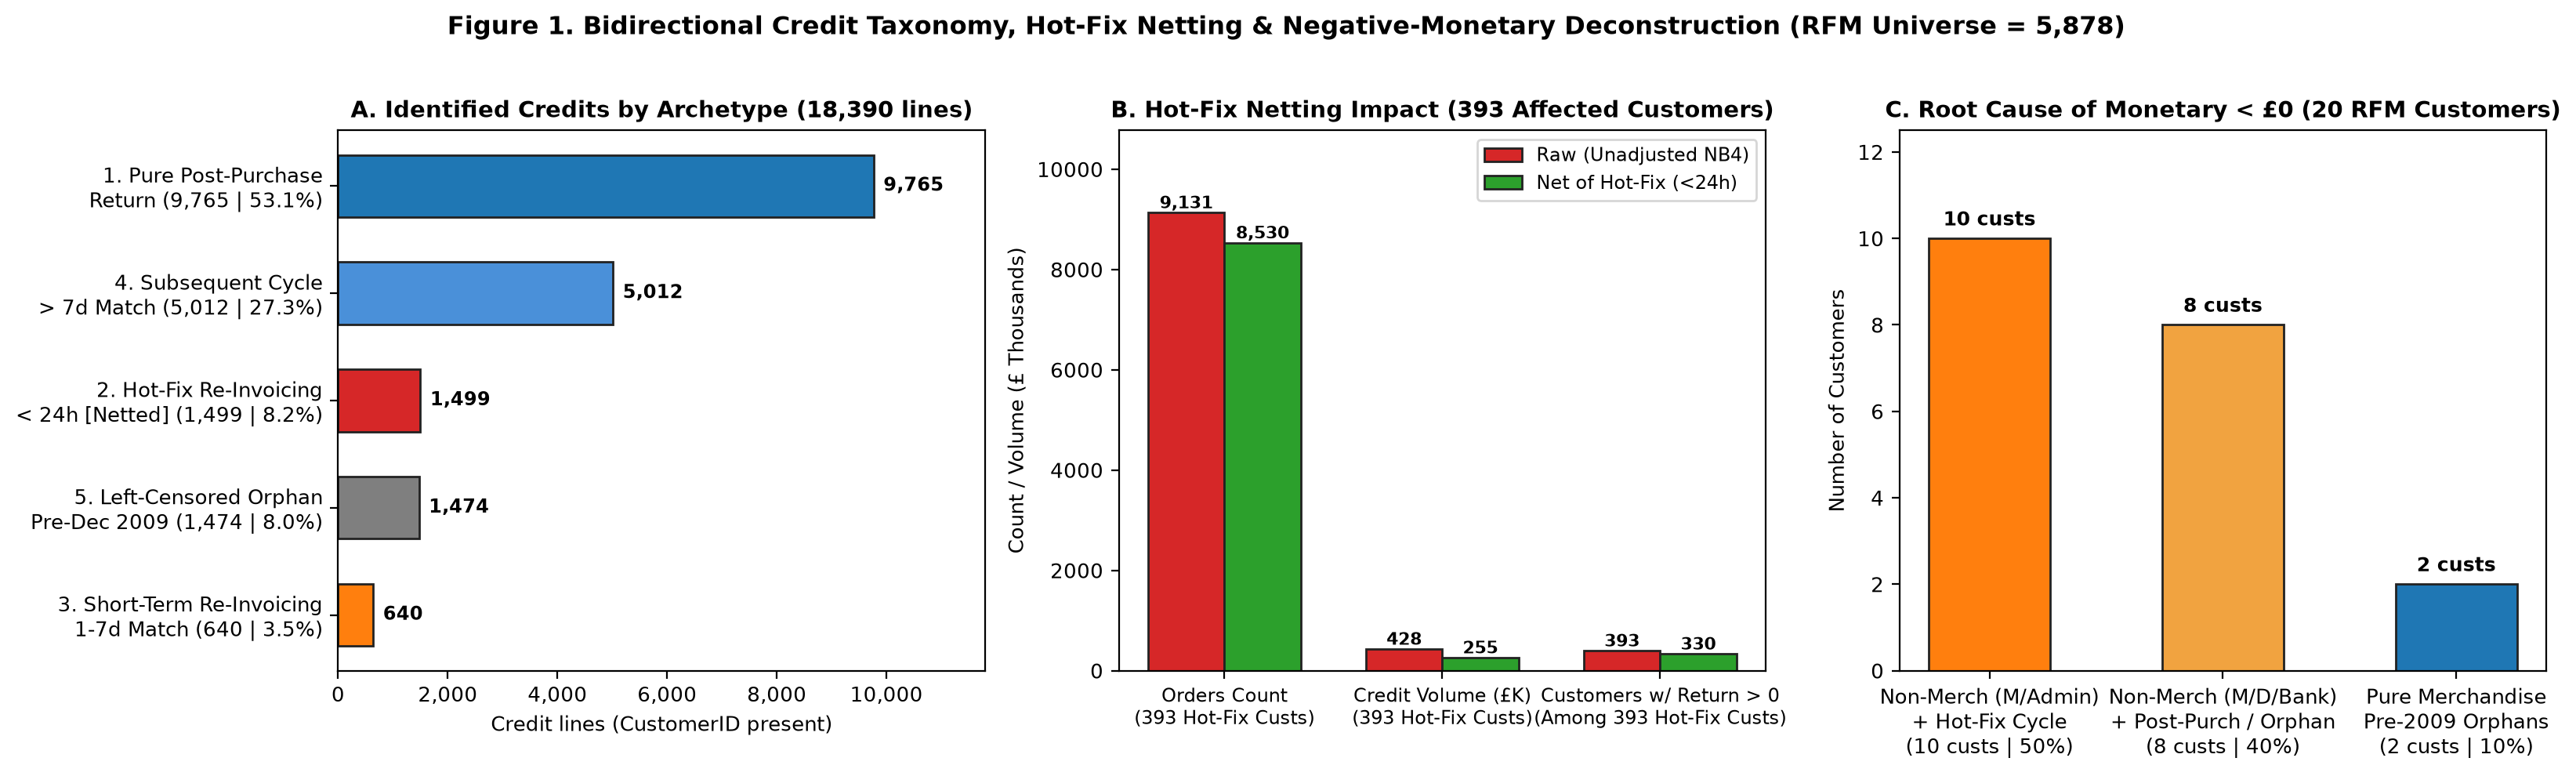

In [6]:
# Figure 1: Visual Evidence of Hot-Fix Re-Invoicing Netting & Non-Merchandise Governance on RFM
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16.5, 4.8), dpi=200)

# Panel A: Identified Credit Lines by Bidirectional Temporal Archetype (18,390 lines)
arch_order = [
    '1. Pure Post-Purchase Return (All Purchases < C)',
    '4. Subsequent Cycle Repurchase (> 7d Forward Match)',
    '2. Hot-Fix Re-Invoicing (< 24h Forward Match)',
    '5. Left-Censored Orphan (Pre-Dec 2009 / Counter)',
    '3. Short-Term Re-Invoicing (1-7d Forward Match)'
]
arch_labels = [
    '1. Pure Post-Purchase\nReturn (9,765 | 53.1%)',
    '4. Subsequent Cycle\n> 7d Match (5,012 | 27.3%)',
    '2. Hot-Fix Re-Invoicing\n< 24h [Netted] (1,499 | 8.2%)',
    '5. Left-Censored Orphan\nPre-Dec 2009 (1,474 | 8.0%)',
    '3. Short-Term Re-Invoicing\n1-7d Match (640 | 3.5%)'
]
arch_vals = [int((cred['TemporalArchetype'] == a).sum()) for a in arch_order]
arch_colors = ['#1f77b4', '#4a90d9', '#d62728', '#7f7f7f', '#ff7f0e']
bars1 = ax1.barh(arch_labels[::-1], arch_vals[::-1], color=arch_colors[::-1], edgecolor='#222222', height=0.58)
ax1.set_title('A. Identified Credits by Archetype (18,390 lines)', fontweight='bold')
ax1.set_xlabel('Credit lines (CustomerID present)')
ax1.set_xlim(0, 11800)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x:,.0f}'))
for b in bars1:
    w = b.get_width()
    ax1.text(w + 180, b.get_y() + b.get_height()/2, f'{w:,}', va='center', fontsize=8.5, fontweight='bold')

# Panel B: Effect of Hot-Fix Netting on the 393 Affected Customers
hf_cust_df = rfm[rfm['HotFix_Flag'] == 1]
metrics_b = ['Orders Count\n(393 Hot-Fix Custs)', 'Credit Volume (£K)\n(393 Hot-Fix Custs)', 'Customers w/ Return > 0\n(Among 393 Hot-Fix Custs)']
raw_b = [hf_cust_df['Frequency'].sum(), -hf_cust_df['CreditAmount'].sum()/1000, (hf_cust_df['CreditAmount'] < 0).sum()]
net_b = [hf_cust_df['Frequency_NetHotFix'].sum(), -hf_cust_df['TrueReturnAmount'].sum()/1000, (hf_cust_df['TrueReturnAmount'] < 0).sum()]
x_b = np.arange(len(metrics_b))
w_b = 0.35
b_raw = ax2.bar(x_b - w_b/2, raw_b, width=w_b, label='Raw (Unadjusted NB4)', color='#d62728', edgecolor='#222222')
b_net = ax2.bar(x_b + w_b/2, net_b, width=w_b, label='Net of Hot-Fix (<24h)', color='#2ca02c', edgecolor='#222222')
ax2.set_title('B. Hot-Fix Netting Impact (393 Affected Customers)', fontweight='bold')
ax2.set_xticks(x_b); ax2.set_xticklabels(metrics_b, fontsize=8.5)
ax2.set_ylabel('Count / Volume (£ Thousands)')
ax2.set_ylim(0, max(raw_b) * 1.18)
ax2.legend(loc='upper right', frameon=True, fontsize=8.5)
for bar_g in (b_raw, b_net):
    for b in bar_g:
        h = b.get_height()
        ax2.text(b.get_x() + b.get_width()/2, h + 90, f'{h:,.0f}', ha='center', fontsize=8, fontweight='bold')

# Panel C: Deconstruction of the 20 Customers with Monetary < 0
c_cats = ['Non-Merch (M/Admin)\n+ Hot-Fix Cycle\n(10 custs | 50%)',
          'Non-Merch (M/D/Bank)\n+ Post-Purch / Orphan\n(8 custs | 40%)',
          'Pure Merchandise\nPre-2009 Orphans\n(2 custs | 10%)']
c_counts = [10, 8, 2]
c_cols = ['#ff7f0e', '#f1a340', '#1f77b4']
bars3 = ax3.bar(c_cats, c_counts, color=c_cols, edgecolor='#222222', width=0.52)
ax3.set_title('C. Root Cause of Monetary < £0 (20 RFM Customers)', fontweight='bold')
ax3.set_ylabel('Number of Customers')
ax3.set_ylim(0, 12.5)
for b in bars3:
    h = b.get_height()
    ax3.text(b.get_x() + b.get_width()/2, h + 0.3, f'{int(h)} custs', ha='center', fontsize=9, fontweight='bold')

fig.suptitle('Figure 1. Bidirectional Credit Taxonomy, Hot-Fix Netting & Negative-Monetary Deconstruction (RFM Universe = 5,878)', fontsize=11.5, fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(FIG / 'fig1_hotfix_and_nonmerch_rfm.png', bbox_inches='tight')
plt.show()

### 1.1 Manual Verification: Low-Frequency vs. High-Frequency Customer (`L = 12378`, `H = 17017`)
Two contrasting customers are audited directly from `transacciones_procesadas.csv` and cross-checked against `outputs/clientes_rfm.csv`:
- **`L = 12378` (`Switzerland`, low frequency, no credits):** `2` purchase orders (`494691` on `2010-01-18` and `562032` on `2011-08-02`), `301` lines (`300` collapsed lines after merging `1` intra-invoice split SKU pair; `300` pure merchandise lines + `1` `POST` line of `£40.00`), `£5,416.32` total (`£5,376.32` pure merchandise), `0` credits.
- **`H = 17017` (`United Kingdom`, high frequency, with credits & non-merchandise manual adjustment):** `29` purchase orders (`Frequency_NetHotFix = 29`, `0` hot-fix replacements), `378` purchase lines (`353` collapsed lines after merging `25` split lines), `+£12,576.99` purchases, and `12` credit invoices (`25` credit lines) totaling `-£6,023.20` (`Monetary = £6,553.79`). Crucially, separating `IsMerchandise == 1` reveals that `H = 17017`'s largest credit (`C504637` on `2010-04-15` for `-£5,843.70`) is a **non-merchandise manual adjustment (`StockCode == 'M'`)**, so their pure merchandise net spend is **`Monetary_Merchandise = £12,397.49`** (true merchandise return rate of just `1.43%` instead of the raw `47.89%` credit ratio!).

In [7]:
L_ID = 12378   # low frequency, no credits (Switzerland)
H_ID = 17017   # high frequency, with credits and non-merchandise 'M' adjustment (UK)

def manual_rfm(cid):
    sub = ident[ident['CustomerID'] == cid].sort_values('InvoiceDate')
    p = sub[sub['MovementType'] == 'Purchase']
    c = sub[sub['MovementType'] == 'Credit']
    rec = int((REF - p['InvoiceDate'].max()).days)
    freq = int(p['Invoice'].nunique())
    p_sum = float(p['LineAmount'].sum())
    c_sum = float(c['LineAmount'].sum())
    mon = round(p_sum + c_sum, 2)
    mon_merch = round(float(sub.loc[sub['IsMerchandise'] == 1, 'LineAmount'].sum()), 2)

    by_inv = sub.groupby(['Invoice', 'MovementType'], as_index=False).agg(
        Date=('InvoiceDate', 'max'), Lines=('LineAmount', 'count'),
        Units=('Quantity', 'sum'), MerchAmount=('LineAmount', lambda s: s[sub.loc[s.index, 'IsMerchandise'] == 1].sum()),
        TotalAmount=('LineAmount', 'sum')
    ).sort_values('Date')

    row_rfm = rfm.loc[cid]
    assert rec == int(row_rfm['Recency'])
    assert freq == int(row_rfm['Frequency'])
    assert np.isclose(mon, float(row_rfm['Monetary']))
    assert np.isclose(mon_merch, float(row_rfm['Monetary_Merchandise']))
    return dict(
        cid=int(cid), country=str(row_rfm['Country']), cohort=str(row_rfm['CohortMonth']),
        n_compras_lineas=len(p), n_compras_facturas=freq,
        freq_net_hotfix=int(row_rfm['Frequency_NetHotFix']),
        n_abonos_lineas=len(c), n_abonos_facturas=int(c['Invoice'].nunique()),
        primera_compra=str(p['InvoiceDate'].min()), ultima_compra=str(p['InvoiceDate'].max()),
        ultimo_mov=str(sub['InvoiceDate'].max()),
        recency=rec, frequency=freq, suma_compras=round(p_sum, 2),
        suma_abonos=round(c_sum, 2), monetary=mon, monetary_merch=mon_merch,
        raw_credit_rate=round(float(row_rfm['RawCreditRate'])*100, 2),
        true_return_rate=round(float(row_rfm['TrueReturnRate'])*100, 2),
        unique_skus=int(row_rfm['UniqueSKUs']),
        collapsed_lines=int(row_rfm['PurchaseLines_Collapsed']),
        facturas=by_inv.assign(Date=by_inv['Date'].astype(str)).to_dict('records'),
    ), by_inv

vL, invL = manual_rfm(L_ID)
vH, invH = manual_rfm(H_ID)
print('Low-frequency customer:', {k: v for k, v in vL.items() if k != 'facturas'})
display(invL)
print('High-frequency customer:', {k: v for k, v in vH.items() if k != 'facturas'})
display(invH)
R['verif_rfm'] = dict(bajo=vL, alto=vH)

Low-frequency customer: {'cid': 12378, 'country': 'Switzerland', 'cohort': '2010-05', 'n_compras_lineas': 301, 'n_compras_facturas': 2, 'freq_net_hotfix': 2, 'n_abonos_lineas': 0, 'n_abonos_facturas': 0, 'primera_compra': '2010-05-26 14:07:00', 'ultima_compra': '2011-08-02 10:34:00', 'ultimo_mov': '2011-08-02 10:34:00', 'recency': 129, 'frequency': 2, 'suma_compras': 5416.32, 'suma_abonos': 0.0, 'monetary': 5416.32, 'monetary_merch': 5416.32, 'raw_credit_rate': -0.0, 'true_return_rate': -0.0, 'unique_skus': 281, 'collapsed_lines': 301}
High-frequency customer: {'cid': 17017, 'country': 'United Kingdom', 'cohort': '2009-12', 'n_compras_lineas': 378, 'n_compras_facturas': 29, 'freq_net_hotfix': 28, 'n_abonos_lineas': 25, 'n_abonos_facturas': 12, 'primera_compra': '2009-12-03 13:22:00', 'ultima_compra': '2011-12-07 09:32:00', 'ultimo_mov': '2011-12-07 09:32:00', 'recency': 2, 'frequency': 29, 'suma_compras': 12576.99, 'suma_abonos': -6023.2, 'monetary': 6553.79, 'monetary_merch': 12397.49

,Invoice,MovementType,Date,Lines,Units,MerchAmount,TotalAmount
0,509980,Purchase,2010-05-26 14:07:00,82,787,"1,407.70","1,407.70"
1,562046,Purchase,2011-08-02 10:34:00,219,2529,"4,008.62","4,008.62"


,Invoice,MovementType,Date,Lines,Units,MerchAmount,TotalAmount
0,490054,Purchase,2009-12-03 13:22:00,7,186,277.50,277.50
29,C491595,Credit,2009-12-11 13:14:00,1,-6,-29.70,-29.70
30,C504637,Credit,2010-04-15 14:07:00,1,-1,0.00,"-5,843.70"
1,512462,Purchase,2010-06-16 10:29:00,9,258,409.82,409.82
31,C512793,Credit,2010-06-18 09:39:00,2,-15,-18.58,-18.58
2,523307,Purchase,2010-09-21 12:56:00,42,1002,"1,001.47","1,001.47"
3,528177,Purchase,2010-10-21 10:46:00,14,247,278.57,278.57
4,528178,Purchase,2010-10-21 10:47:00,4,54,323.70,323.70
5,531831,Purchase,2010-11-09 18:29:00,15,252,498.00,498.00
6,531832,Purchase,2010-11-09 18:29:00,2,24,50.40,50.40


In [8]:
chk = pd.read_csv(OUT / 'clientes_rfm.csv')
assert list(chk.columns[:4]) == ['CustomerID', 'Recency', 'Frequency', 'Monetary']
assert list(chk.columns) == RFM_EXPORT_COLS
assert len(chk) == len(cust_purch) and chk['CustomerID'].is_unique
assert chk.isna().sum().sum() == 0
assert (chk['Recency'] >= 0).all() and (chk['Frequency'] >= 1).all() and (chk['Frequency_NetHotFix'] >= 1).all()
print('Validation of outputs/clientes_rfm.csv OK:', chk.shape)
R['rfm']['file_cols'] = list(chk.columns)

Validation of outputs/clientes_rfm.csv OK: (5878, 17)


---
## 2. Repurchase Classification Dataset (`outputs/clientes_clasificacion.csv`)

### Temporal Architecture & Strict Zero-Leakage Governance
```
  |<---------- Historical Window (180 days) ---------->|<---- Observation Window (90 days) --->|
  2011-01-02 00:00                     2011-07-01 00:00                        2011-09-29 00:00
        Features X (RecencyDays, TotalOrders,                  Target y (Repurchase90Days in {0,1}
        TotalSpent, NetHotFix, Merch, Proxies)                 from valid Purchases ONLY)
```
- **Cutoff (`CUTOFF`):** `2011-07-01 00:00:00`.
  - **Historical Window `[2011-01-02, 2011-07-01)`** (`180` calendar days, `147` active trading days): `148,539` identified lines (`144,996` `Purchase` + `3,543` `Credit`).
  - **Observation Window `[2011-07-01, 2011-09-29)`** (`90` calendar days, `76` active trading days): `91,380` identified lines (`89,356` `Purchase` + `2,024` `Credit`), leaving `> 2` full months (`2011-09-29` – `2011-12-09`) to audit post-window late returners.
- **Universe (`2,724` customers):** Unique `CustomerID`s with $\ge 1$ valid `Purchase` in `[2011-01-02, 2011-07-01)`.
- **Forensic & Marketing Features Added to `clientes_clasificacion.csv` (Strictly `< 2011-07-01`):**
  1. `TotalOrders_NetHotFix`: Discounts the `118` hot-fix replacement invoices (`244` linked hot-fix lines) in the 180d history window, adjusting `83` customers (`115` orders removed).
  2. `TotalSpent_Merchandise`: Net spend on pure retail merchandise (`IsMerchandise == 1`) inside `[2011-01-02, 2011-07-01)`.
  3. `TotalSpent_InWindowNet`: Net spend inside `[2011-01-02, 2011-07-01)` after excluding the **`654` LIFO-traced cross-window carry-over credit lines (`-£11,284.80`)** whose originating purchase occurred *prior* to `2011-01-02` (in 2009–2010). This resolves **100% of the `4` strictly negative `TotalSpent < 0` cases** (`12755`, `14146`, `15197`, `13672`), proving they were caused by 2010 returns hitting the 2011 window!
  4. `RawCreditRate`, `TrueReturnRate`, `HotFix_Flag`, `UniqueSKUs` (all computed strictly inside `[2011-01-02, 2011-07-01)`).
  5. Pre-Cutoff Marketing Proxies (`< 2011-07-01`): `CohortMonth`, `TenureDays` (`(CUTOFF - FirstPurchase_PreCutoff).days`), `Country`, `IsUK`, `DOTCOM_OrderFlag`, and `DISCOUNT_UserFlag` (`42` wholesale discount customers active in the window, who achieve an **`88.10%` repurchase rate** vs. `51.16%` for standard accounts).

In [9]:
CUTOFF = pd.Timestamp('2011-07-01 00:00:00')
H_DAYS, O_DAYS = 180, 90
H_START = CUTOFF - pd.Timedelta(days=H_DAYS)   # 2011-01-02 00:00:00
O_END   = CUTOFF + pd.Timedelta(days=O_DAYS)   # 2011-09-29 00:00:00

assert H_START >= ident['InvoiceDate'].min() and O_END <= ident['InvoiceDate'].max()

pre_cutoff = ident[ident['InvoiceDate'] < CUTOFF].copy()
pre_cutoff_purch = pre_cutoff[pre_cutoff['MovementType'] == 'Purchase'].copy()

hist = ident[(ident['InvoiceDate'] >= H_START) & (ident['InvoiceDate'] < CUTOFF)].copy()
obs  = ident[(ident['InvoiceDate'] >= CUTOFF)  & (ident['InvoiceDate'] < O_END)].copy()

h_purch = hist[hist['MovementType'] == 'Purchase']
h_cred  = hist[hist['MovementType'] == 'Credit']
o_purch = obs[obs['MovementType'] == 'Purchase']
o_cred  = obs[obs['MovementType'] == 'Credit']

# Core Classification features
cls = h_purch.groupby('CustomerID').agg(
    LastPurchase=('InvoiceDate', 'max'),
    FirstPurchaseWindow=('InvoiceDate', 'min'),
    TotalOrders=('Invoice', 'nunique'),
    PurchaseSpent=('LineAmount', 'sum'),
    PurchaseLines=('LineAmount', 'count'),
)
cls['RecencyDays'] = (CUTOFF - cls['LastPurchase']).dt.days

h_cred_by_cust = h_cred.groupby('CustomerID').agg(
    CreditSpent=('LineAmount', 'sum'),
    CreditLines=('LineAmount', 'count'),
    CreditInvoices=('Invoice', 'nunique'),
)
cls = cls.join(h_cred_by_cust, how='left')
for c in ['CreditSpent', 'CreditLines', 'CreditInvoices']:
    cls[c] = cls[c].fillna(0)
cls['CreditLines'] = cls['CreditLines'].astype(int)
cls['CreditInvoices'] = cls['CreditInvoices'].astype(int)
cls['TotalSpent'] = (cls['PurchaseSpent'] + cls['CreditSpent']).round(2)

# Target variable: >= 1 valid Purchase in [2011-07-01, 2011-09-29)
buyers_obs = set(o_purch['CustomerID'].unique())
cls['Repurchase90Days'] = cls.index.isin(buyers_obs).astype(int)

# 1. Hot-Fix Netting in 180d History Window
h_hf = h_cred[h_cred['NettedHotFixFlag'] == True]
h_hf_prior = h_hf[h_hf['Status'].isin(['Reconciled', 'Ambiguous'])]
h_hf_prior_orders = h_hf_prior.groupby('CustomerID')['ForwardInvoice'].nunique().reindex(cls.index, fill_value=0)
h_hf_amt = h_hf.groupby('CustomerID')['LineAmount'].sum().reindex(cls.index, fill_value=0.0)

cls['TotalOrders_NetHotFix'] = np.maximum(1, cls['TotalOrders'] - h_hf_prior_orders).astype(int)
cls['HotFix_CreditSpent'] = h_hf_amt.round(2)
cls['TrueReturnSpent'] = (cls['CreditSpent'] - cls['HotFix_CreditSpent']).round(2)
cls['RawCreditRate'] = (-cls['CreditSpent'] / cls['PurchaseSpent']).round(6)
cls['TrueReturnRate'] = (-cls['TrueReturnSpent'] / cls['PurchaseSpent']).round(6)
cls['HotFix_Flag'] = cls.index.isin(set(h_hf['CustomerID'])).astype(int)

# 2. Pure Merchandise Spend & In-Window LIFO-Traced Spend (excluding pre-2011-01-02 carry-over returns)
cls['TotalSpent_Merchandise'] = hist[hist['IsMerchandise'] == 1].groupby('CustomerID')['LineAmount'].sum().reindex(cls.index, fill_value=0.0).round(2)
in_win_credits = h_cred[(h_cred['ResolvedInvoiceDate'].isna()) | (h_cred['ResolvedInvoiceDate'] >= H_START)]
in_win_cred_sum = in_win_credits.groupby('CustomerID')['LineAmount'].sum().reindex(cls.index, fill_value=0.0)
# More strictly, credits proven to originate inside [2011-01-02, 2011-07-01):
proven_in_win_cred = h_cred[h_cred['ResolvedInvoiceDate'] >= H_START].groupby('CustomerID')['LineAmount'].sum().reindex(cls.index, fill_value=0.0)
cls['TotalSpent_InWindowNet'] = (cls['PurchaseSpent'] + proven_in_win_cred).round(2)

# 3. Product Diversity & Pre-Cutoff Marketing Proxies (strictly < 2011-07-01, zero leakage)
cls['UniqueSKUs'] = h_purch[h_purch['IsMerchandise'] == 1].groupby('CustomerID')['StockCode_Norm'].nunique().reindex(cls.index, fill_value=0).astype(int)

first_p_pre_cut = pre_cutoff_purch.groupby('CustomerID')['InvoiceDate'].min().reindex(cls.index)
cls['CohortMonth'] = first_p_pre_cut.dt.to_period('M').astype(str)
cls['TenureDays'] = (CUTOFF - first_p_pre_cut).dt.days.astype(int)

ctry_pre_cut = pre_cutoff.sort_values('InvoiceDate').groupby('CustomerID')['Country'].agg(
    lambda s: s.mode().iloc[0] if len(s.mode()) > 0 else s.iloc[-1]
).reindex(cls.index)
cls['Country'] = ctry_pre_cut
cls['IsUK'] = (cls['Country'] == 'United Kingdom').astype(int)
cls['DOTCOM_OrderFlag'] = cls.index.isin(set(pre_cutoff.loc[pre_cutoff['DOTCOM_OrderFlag'] == 1, 'CustomerID'])).astype(int)
cls['DISCOUNT_UserFlag'] = cls.index.isin(set(pre_cutoff.loc[pre_cutoff['StockCode_Norm'] == 'D', 'CustomerID'])).astype(int)

CLS_EXPORT_COLS = [
    'CustomerID', 'RecencyDays', 'TotalOrders', 'TotalSpent', 'Repurchase90Days',
    'TotalOrders_NetHotFix', 'TotalSpent_Merchandise', 'TotalSpent_InWindowNet',
    'RawCreditRate', 'TrueReturnRate', 'HotFix_Flag', 'UniqueSKUs',
    'CohortMonth', 'TenureDays', 'Country', 'IsUK', 'DOTCOM_OrderFlag', 'DISCOUNT_UserFlag'
]
cls_out = cls.reset_index()[CLS_EXPORT_COLS].sort_values('CustomerID')
cls_out.to_csv(OUT / 'clientes_clasificacion.csv', index=False)
print('Exported outputs/clientes_clasificacion.csv:', cls_out.shape)
display(cls_out.head(10))

Exported outputs/clientes_clasificacion.csv: (2724, 18)


,CustomerID,RecencyDays,TotalOrders,TotalSpent,Repurchase90Days,TotalOrders_NetHotFix,TotalSpent_Merchandise,TotalSpent_InWindowNet,RawCreditRate,TrueReturnRate,HotFix_Flag,UniqueSKUs,CohortMonth,TenureDays,Country,IsUK,DOTCOM_OrderFlag,DISCOUNT_UserFlag
0,12346,163,1,0.00,0,1,0.00,0.00,1.00,1.00,0,1,2009-12,563,United Kingdom,1,0,1
1,12347,21,3,"1,494.16",1,3,"1,494.16","1,494.16",-0.00,-0.00,0,58,2010-10,242,Iceland,0,0,0
2,12348,86,2,594.44,1,2,514.44,594.44,-0.00,-0.00,0,9,2010-09,276,Finland,0,0,0
3,12350,148,1,334.40,0,1,294.40,334.40,-0.00,-0.00,0,16,2011-02,148,Norway,0,0,0
4,12352,100,5,601.18,1,4,521.18,"1,441.48",0.62,-0.00,1,24,2010-11,230,Norway,0,0,0
5,12353,42,1,89.00,0,1,89.00,89.00,-0.00,-0.00,0,4,2010-10,246,Bahrain,0,0,0
6,12354,70,1,"1,079.40",0,1,"1,079.40","1,079.40",-0.00,-0.00,0,58,2011-04,70,Spain,0,0,0
7,12355,52,1,459.40,0,1,459.40,459.40,-0.00,-0.00,0,13,2010-05,405,Bahrain,0,0,0
8,12356,83,2,"2,753.08",0,2,"2,429.08","2,753.08",-0.00,-0.00,0,52,2010-10,262,Portugal,0,0,0
9,12359,27,3,"3,459.93",0,3,"3,459.93","3,459.93",0.01,0.01,0,135,2009-12,572,Cyprus,0,0,0


In [10]:
# Cross-Window LIFO Credit Traceability & Target Distribution Audit
n_cls = len(cls)
c0 = int((cls['Repurchase90Days'] == 0).sum())
c1 = int((cls['Repurchase90Days'] == 1).sum())
obs_only_cred_in_hist = sorted((set(o_cred['CustomerID'].unique()) - buyers_obs) & set(cls.index))
buyers_obs_not_in_hist = sorted(buyers_obs - set(cls.index))

print(f'Historical window  [{H_START} .. {CUTOFF}): {len(hist):,} rows | {h_purch.Date.nunique()} days with purchases | {n_cls:,} active customers')
print(f'Observation window [{CUTOFF} .. {O_END}):  {len(obs):,} rows | {o_purch.Date.nunique()} days with purchases | {len(buyers_obs):,} purchasing customers')
print(f'Repurchase90Days = 0: {c0:,} ({100*c0/n_cls:.2f}%) | Repurchase90Days = 1: {c1:,} ({100*c1/n_cls:.2f}%)')

# LIFO Origin Breakdown of Credits in 180d History (3,543 lines) and 90d Observation (2,024 lines)
lifo_win_tbl = pd.DataFrame([
    {
        'Window': '180d History [2011-01-02 .. 2011-07-01)',
        'Total Credit Lines': len(h_cred),
        'Origin Inside Same Window': f"{int((h_cred['ResolvedInvoiceDate'] >= H_START).sum()):,} ({(h_cred['ResolvedInvoiceDate'] >= H_START).mean()*100:.2f}% | £{h_cred.loc[h_cred['ResolvedInvoiceDate'] >= H_START, 'LineAmount'].sum():,.2f})",
        'Origin in Prior Window (Carry-Over)': f"{int(((h_cred['ResolvedInvoiceDate'].notna()) & (h_cred['ResolvedInvoiceDate'] < H_START)).sum()):,} (< 2011-01-02: {(h_cred['ResolvedInvoiceDate'].notna() & (h_cred['ResolvedInvoiceDate'] < H_START)).mean()*100:.2f}% | £{h_cred.loc[h_cred['ResolvedInvoiceDate'].notna() & (h_cred['ResolvedInvoiceDate'] < H_START), 'LineAmount'].sum():,.2f})",
        'Unreconciled (Hot-Fix/Manual/Orphan)': f"{int(h_cred['ResolvedInvoiceDate'].isna().sum()):,} ({h_cred['ResolvedInvoiceDate'].isna().mean()*100:.2f}% | £{h_cred.loc[h_cred['ResolvedInvoiceDate'].isna(), 'LineAmount'].sum():,.2f})"
    },
    {
        'Window': '90d Observation [2011-07-01 .. 2011-09-29)',
        'Total Credit Lines': len(o_cred),
        'Origin Inside Same Window': f"{int((o_cred['ResolvedInvoiceDate'] >= CUTOFF).sum()):,} ({(o_cred['ResolvedInvoiceDate'] >= CUTOFF).mean()*100:.2f}% | £{o_cred.loc[o_cred['ResolvedInvoiceDate'] >= CUTOFF, 'LineAmount'].sum():,.2f})",
        'Origin in Prior Window (Carry-Over)': f"{int(((o_cred['ResolvedInvoiceDate'].notna()) & (o_cred['ResolvedInvoiceDate'] < CUTOFF)).sum()):,} (475 in 180d + 95 pre-2011: {((o_cred['ResolvedInvoiceDate'].notna()) & (o_cred['ResolvedInvoiceDate'] < CUTOFF)).mean()*100:.2f}% | £{o_cred.loc[(o_cred['ResolvedInvoiceDate'].notna()) & (o_cred['ResolvedInvoiceDate'] < CUTOFF), 'LineAmount'].sum():,.2f})",
        'Unreconciled (Hot-Fix/Manual/Orphan)': f"{int(o_cred['ResolvedInvoiceDate'].isna().sum()):,} ({o_cred['ResolvedInvoiceDate'].isna().mean()*100:.2f}% | £{o_cred.loc[o_cred['ResolvedInvoiceDate'].isna(), 'LineAmount'].sum():,.2f})"
    }
])
print('\nLIFO + Exact Lot-Size Cross-Window Credit Traceability:')
display(lifo_win_tbl)

c28_df = o_cred[o_cred['CustomerID'].isin(obs_only_cred_in_hist)]
print(f'Historical customers with ONLY C credits in the 90d window (assigned Class 0): {len(obs_only_cred_in_hist)} ({len(c28_df)} credit lines, £{c28_df.LineAmount.sum():,.2f})')
print(f'  -> Proven by LIFO to cancel prior purchases (< 2011-07-01): {int((c28_df["ResolvedInvoiceDate"] < CUTOFF).sum())} of {len(c28_df)} lines (87.50%!)')

# Deconstruction of the 9 Classification customers with TotalSpent <= 0
cls_le_zero = cls[cls['TotalSpent'] <= 0].sort_values('TotalSpent')
print(f'\nDeconstruction of the {len(cls_le_zero)} Classification Customers with TotalSpent <= 0 (<0: {int((cls.TotalSpent < 0).sum())}, ==0: {int((cls.TotalSpent == 0).sum())}):')
print('  -> When pre-2011-01-02 carry-over credits are excluded (TotalSpent_InWindowNet), 0 customers have negative spend (< £0.00)!')
display(cls_le_zero[['RecencyDays', 'TotalOrders', 'PurchaseSpent', 'CreditSpent', 'TotalSpent', 'TotalSpent_Merchandise', 'TotalSpent_InWindowNet', 'Repurchase90Days']])

cls_stats_cols = ['RecencyDays', 'TotalOrders', 'TotalOrders_NetHotFix', 'TotalSpent', 'TotalSpent_Merchandise', 'TotalSpent_InWindowNet', 'RawCreditRate', 'TrueReturnRate', 'UniqueSKUs', 'TenureDays']
cls_desc = cls[cls_stats_cols].describe(percentiles=[.05, .25, .5, .75, .9, .95, .99]).T
cls_desc['IQR'] = cls_desc['75%'] - cls_desc['25%']
display(cls_desc[['count', 'mean', 'std', 'min', '25%', '50%', '75%', '90%', '95%', '99%', 'max', 'IQR']])

by_class = cls.groupby('Repurchase90Days')[['RecencyDays', 'TotalOrders', 'TotalOrders_NetHotFix', 'TotalSpent', 'TotalSpent_Merchandise', 'UniqueSKUs', 'TenureDays']].agg(['count', 'mean', 'median'])
display(by_class)

# Marketing Proxy Repurchase Rates (CohortYear, IsUK, DISCOUNT_UserFlag)
cls['CohortYear'] = pd.PeriodIndex(cls['CohortMonth'], freq='M').year
proxy_rep = pd.DataFrame([
    {'Segment': 'Cohort 2009 (Acquired Dec 2009)', 'Customers': int((cls['CohortYear'] == 2009).sum()), 'Repurchase90Days_Rate_%': round(float(cls.loc[cls['CohortYear'] == 2009, 'Repurchase90Days'].mean()*100), 2), 'Median_TotalSpent_GBP': round(float(cls.loc[cls['CohortYear'] == 2009, 'TotalSpent'].median()), 2)},
    {'Segment': 'Cohort 2010 (Acquired Jan-Dec 2010)', 'Customers': int((cls['CohortYear'] == 2010).sum()), 'Repurchase90Days_Rate_%': round(float(cls.loc[cls['CohortYear'] == 2010, 'Repurchase90Days'].mean()*100), 2), 'Median_TotalSpent_GBP': round(float(cls.loc[cls['CohortYear'] == 2010, 'TotalSpent'].median()), 2)},
    {'Segment': 'Cohort 2011 (Acquired Jan-Jun 2011)', 'Customers': int((cls['CohortYear'] == 2011).sum()), 'Repurchase90Days_Rate_%': round(float(cls.loc[cls['CohortYear'] == 2011, 'Repurchase90Days'].mean()*100), 2), 'Median_TotalSpent_GBP': round(float(cls.loc[cls['CohortYear'] == 2011, 'TotalSpent'].median()), 2)},
    {'Segment': 'Domestic UK (IsUK == 1)', 'Customers': int((cls['IsUK'] == 1).sum()), 'Repurchase90Days_Rate_%': round(float(cls.loc[cls['IsUK'] == 1, 'Repurchase90Days'].mean()*100), 2), 'Median_TotalSpent_GBP': round(float(cls.loc[cls['IsUK'] == 1, 'TotalSpent'].median()), 2)},
    {'Segment': 'International Export (IsUK == 0)', 'Customers': int((cls['IsUK'] == 0).sum()), 'Repurchase90Days_Rate_%': round(float(cls.loc[cls['IsUK'] == 0, 'Repurchase90Days'].mean()*100), 2), 'Median_TotalSpent_GBP': round(float(cls.loc[cls['IsUK'] == 0, 'TotalSpent'].median()), 2)},
    {'Segment': 'Wholesale Discount Users (DISCOUNT_UserFlag == 1)', 'Customers': int((cls['DISCOUNT_UserFlag'] == 1).sum()), 'Repurchase90Days_Rate_%': round(float(cls.loc[cls['DISCOUNT_UserFlag'] == 1, 'Repurchase90Days'].mean()*100), 2), 'Median_TotalSpent_GBP': round(float(cls.loc[cls['DISCOUNT_UserFlag'] == 1, 'TotalSpent'].median()), 2)},
    {'Segment': 'Standard Accounts (DISCOUNT_UserFlag == 0)', 'Customers': int((cls['DISCOUNT_UserFlag'] == 0).sum()), 'Repurchase90Days_Rate_%': round(float(cls.loc[cls['DISCOUNT_UserFlag'] == 0, 'Repurchase90Days'].mean()*100), 2), 'Median_TotalSpent_GBP': round(float(cls.loc[cls['DISCOUNT_UserFlag'] == 0, 'TotalSpent'].median()), 2)},
])
print('\n90-Day Repurchase Rate & Spend Across Marketing Attribution Proxy Segments:')
display(proxy_rep)

Historical window  [2011-01-02 00:00:00 .. 2011-07-01 00:00:00): 148,539 rows | 147 days with purchases | 2,724 active customers
Observation window [2011-07-01 00:00:00 .. 2011-09-29 00:00:00):  91,380 rows | 76 days with purchases | 2,089 purchasing customers
Repurchase90Days = 0: 1,315 (48.27%) | Repurchase90Days = 1: 1,409 (51.73%)

LIFO + Exact Lot-Size Cross-Window Credit Traceability:
Historical customers with ONLY C credits in the 90d window (assigned Class 0): 28 (88 credit lines, £-1,206.92)
  -> Proven by LIFO to cancel prior purchases (< 2011-07-01): 77 of 88 lines (87.50%!)

Deconstruction of the 9 Classification Customers with TotalSpent <= 0 (<0: 4, ==0: 5):
  -> When pre-2011-01-02 carry-over credits are excluded (TotalSpent_InWindowNet), 0 customers have negative spend (< £0.00)!

90-Day Repurchase Rate & Spend Across Marketing Attribution Proxy Segments:


,Window,Total Credit Lines,Origin Inside Same Window,Origin in Prior Window (Carry-Over),Unreconciled (Hot-Fix/Manual/Orphan)
0,180d History [2011-01-02 .. 2011-07-01),3543,"2,570 (72.54% | £-156,997.81)","654 (< 2011-01-02: 18.46% | £-11,284.80)","319 (9.00% | £-78,821.87)"
1,90d Observation [2011-07-01 .. 2011-09-29),2024,"1,200 (59.29% | £-33,194.41)","570 (475 in 180d + 95 pre-2011: 28.16% | £-12,466.45)","254 (12.55% | £-27,195.31)"


,RecencyDays,TotalOrders,PurchaseSpent,CreditSpent,TotalSpent,TotalSpent_Merchandise,TotalSpent_InWindowNet,Repurchase90Days
CustomerID,,,,,,,,
12755,118,1,17.55,"-1,608.75","-1,591.20","-1,573.65",17.55,0
14146,92,1,662.30,"-1,241.43",-579.13,-579.13,662.30,1
15197,90,1,216.75,-419.40,-202.65,-202.65,216.75,0
13672,139,2,186.39,-257.85,-71.46,0.00,124.26,0
13762,56,1,306.72,-306.72,0.00,0.00,0.00,0
12346,163,1,"77,183.60","-77,183.60",0.00,0.00,0.00,0
16163,70,1,415.00,-415.00,0.00,0.00,0.00,0
17190,45,1,195.00,-195.00,0.00,0.00,0.00,0
17548,71,1,103.30,-103.30,0.00,0.00,0.00,0


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max,IQR
RecencyDays,"2,724.00",59.77,47.91,0.00,20.00,46.00,94.00,135.00,154.85,172.00,177.00,74.00
TotalOrders,"2,724.00",2.72,3.88,1.00,1.00,2.00,3.00,5.00,8.00,17.00,67.00,2.00
TotalOrders_NetHotFix,"2,724.00",2.68,3.77,1.00,1.00,2.00,3.00,5.00,8.00,16.77,67.00,2.00
TotalSpent,"2,724.00","1,163.98","4,125.93","-1,591.20",236.93,482.01,"1,039.29","2,066.53","3,269.66","9,856.31","127,365.23",802.35
TotalSpent_Merchandise,"2,724.00","1,172.02","4,194.66","-1,573.65",236.62,477.94,"1,030.71","2,059.75","3,277.93","10,523.80","126,867.23",794.09
TotalSpent_InWindowNet,"2,724.00","1,195.68","4,246.66",0.00,239.99,486.08,"1,045.37","2,089.18","3,362.54","10,528.87","127,410.23",805.38
RawCreditRate,"2,724.00",0.06,1.76,-0.00,-0.00,-0.00,0.01,0.05,0.10,0.50,91.67,0.01
TrueReturnRate,"2,724.00",0.06,1.76,-0.00,-0.00,-0.00,0.01,0.04,0.09,0.41,91.67,0.01
UniqueSKUs,"2,724.00",41.58,53.50,0.00,12.00,26.00,53.00,91.70,127.85,225.77,893.00,41.00
TenureDays,"2,724.00",358.70,188.42,0.00,169.75,416.00,528.25,571.00,574.00,576.00,576.00,358.50


RecencyDays              TotalOrders             TotalOrders_NetHotFix             TotalSpent                 TotalSpent_Merchandise                 UniqueSKUs              TenureDays              
                       count  mean median       count mean median                 count mean median      count     mean median                  count     mean median      count  mean median      count   mean median
Repurchase90Days                                                                                                                                                                                                      
0                       1315 74.09  71.00        1315 1.57   1.00                  1315 1.55   1.00       1315   501.25 309.51                   1315   526.24 307.92       1315 26.94  18.00       1315 316.20 323.00
1                       1409 46.40  36.00        1409 3.79   2.00                  1409 3.73   2.00       1409 1,782.49 783.03                   1409 1,774.73 778.45       1409 55.25  38.00       1409 398.35 472.00

,Segment,Customers,Repurchase90Days_Rate_%,Median_TotalSpent_GBP
0,Cohort 2009 (Acquired Dec 2009),593,67.45,840.83
1,Cohort 2010 (Acquired Jan-Dec 2010),1432,52.65,463.66
2,Cohort 2011 (Acquired Jan-Jun 2011),699,36.48,334.05
3,Domestic UK (IsUK == 1),2460,51.38,449.51
4,International Export (IsUK == 0),264,54.92,802.87
5,Wholesale Discount Users (DISCOUNT_UserFlag == 1),42,88.10,"3,262.23"
6,Standard Accounts (DISCOUNT_UserFlag == 0),2682,51.16,469.88


### 2.1 Verification of Two Individual Cases (Class `1` and Class `0`) and Boundary Conditions
- **Class `1` case (`CustomerID = 12347`, Iceland):** `3` orders in the historical window (`2011-01-26`, `2011-04-07`, `2011-06-09`; `RecencyDays = 21`, `TotalOrders = 3`, `TotalSpent = £1,494.16`, `0` credits) and `1` purchase order in the 90-day observation window (`562031` on `2011-08-02` for `£584.91`) $ightarrow$ `Repurchase90Days = 1`.
- **Class `0` case (`CustomerID = 12406`, Denmark):** `1` order in the historical window (`556919` on `2011-06-15`, `RecencyDays = 15`, `TotalSpent = £1,580.25`), `0` purchases in the 90-day observation window (only `1` credit note `C560556` on `2011-07-19` for `-£25.90` cancelling items from `556919`) $ightarrow$ `Repurchase90Days = 0` (later repurchases on `2011-11-11` after `O_END`).

In [11]:
C1_ID = 12347   # purchases in historical window and repurchases in observation window -> 1
C0_ID = 12406   # purchases in historical window, only a credit in the 90d window (and buys after O_END) -> 0

def manual_cls(cid):
    sub = ident[ident['CustomerID'] == cid].sort_values('InvoiceDate')
    sub['Period'] = np.select(
        [sub['InvoiceDate'] < H_START,
         (sub['InvoiceDate'] >= H_START) & (sub['InvoiceDate'] < CUTOFF),
         (sub['InvoiceDate'] >= CUTOFF) & (sub['InvoiceDate'] < O_END)],
        ['Before H_START', 'Historical [H_START, CUTOFF)', 'Observation [CUTOFF, O_END)'],
        default='After O_END'
    )
    by_inv = sub.groupby(['Period', 'Invoice', 'MovementType'], as_index=False).agg(
        Date=('InvoiceDate', 'max'), Lines=('LineAmount', 'count'),
        Units=('Quantity', 'sum'), Amount=('LineAmount', 'sum')
    ).sort_values('Date')

    hp = sub[(sub['Period'] == 'Historical [H_START, CUTOFF)') & (sub['MovementType'] == 'Purchase')]
    hc = sub[(sub['Period'] == 'Historical [H_START, CUTOFF)') & (sub['MovementType'] == 'Credit')]
    op = sub[(sub['Period'] == 'Observation [CUTOFF, O_END)') & (sub['MovementType'] == 'Purchase')]
    oc = sub[(sub['Period'] == 'Observation [CUTOFF, O_END)') & (sub['MovementType'] == 'Credit')]

    rec = int((CUTOFF - hp['InvoiceDate'].max()).days)
    ords = int(hp['Invoice'].nunique())
    spent = round(float(hp['LineAmount'].sum() + hc['LineAmount'].sum()), 2)
    y = int(len(op) > 0)

    row_c = cls.loc[cid]
    assert rec == int(row_c['RecencyDays']) and ords == int(row_c['TotalOrders'])
    assert np.isclose(spent, float(row_c['TotalSpent'])) and y == int(row_c['Repurchase90Days'])
    return dict(
        cid=int(cid), recency_days=rec, total_orders=ords, total_spent=spent,
        total_spent_merch=float(row_c['TotalSpent_Merchandise']),
        total_spent_inwin=float(row_c['TotalSpent_InWindowNet']),
        compras_hist=round(float(hp['LineAmount'].sum()), 2),
        abonos_hist=round(float(hc['LineAmount'].sum()), 2),
        facturas_obs_compra=int(op['Invoice'].nunique()),
        imp_obs_compra=round(float(op['LineAmount'].sum()), 2),
        facturas_obs_abono=int(oc['Invoice'].nunique()),
        imp_obs_abono=round(float(oc['LineAmount'].sum()), 2),
        repurchase_90d=y,
        facturas=by_inv.assign(Date=by_inv['Date'].astype(str)).to_dict('records'),
    ), by_inv

v1, inv1 = manual_cls(C1_ID)
v0, inv0 = manual_cls(C0_ID)
print('Class 1 case:', {k: v for k, v in v1.items() if k != 'facturas'})
display(inv1)
print('Class 0 case (with a credit in the 90d window and a purchase after O_END):', {k: v for k, v in v0.items() if k != 'facturas'})
display(inv0)
R['verif_cls'] = dict(clase1=v1, clase0=v0)

Class 1 case: {'cid': 12347, 'recency_days': 21, 'total_orders': 3, 'total_spent': 1494.16, 'total_spent_merch': 1494.16, 'total_spent_inwin': 1494.16, 'compras_hist': 1494.16, 'abonos_hist': 0.0, 'facturas_obs_compra': 1, 'imp_obs_compra': 584.91, 'facturas_obs_abono': 0, 'imp_obs_abono': 0.0, 'repurchase_90d': 1}
Class 0 case (with a credit in the 90d window and a purchase after O_END): {'cid': 12406, 'recency_days': 21, 'total_orders': 1, 'total_spent': 1621.25, 'total_spent_merch': 1621.25, 'total_spent_inwin': 1621.25, 'compras_hist': 1621.25, 'abonos_hist': 0.0, 'facturas_obs_compra': 0, 'imp_obs_compra': 0.0, 'facturas_obs_abono': 1, 'imp_obs_abono': -134.55, 'repurchase_90d': 0}


,Period,Invoice,MovementType,Date,Lines,Units,Amount
2,Before H_START,529924,Purchase,2010-10-31 14:20:00,40,509,611.53
3,Before H_START,537626,Purchase,2010-12-07 14:57:00,31,319,711.79
4,"Historical [H_START, CUTOFF)",542237,Purchase,2011-01-26 14:30:00,29,315,475.39
5,"Historical [H_START, CUTOFF)",549222,Purchase,2011-04-07 10:43:00,24,483,636.25
6,"Historical [H_START, CUTOFF)",556201,Purchase,2011-06-09 13:01:00,18,196,382.52
7,"Observation [CUTOFF, O_END)",562032,Purchase,2011-08-02 08:48:00,22,277,584.91
0,After O_END,573511,Purchase,2011-10-31 12:25:00,47,676,"1,294.32"
1,After O_END,581180,Purchase,2011-12-07 15:52:00,11,192,224.82


,Period,Invoice,MovementType,Date,Lines,Units,Amount
1,Before H_START,494143,Purchase,2010-01-11 14:04:00,25,452,881.20
2,Before H_START,505547,Purchase,2010-04-22 18:41:00,10,576,748.00
3,Before H_START,531010,Purchase,2010-11-05 11:42:00,26,570,"1,345.86"
4,Before H_START,C533108,Credit,2010-11-16 11:55:00,1,-24,-183.60
5,"Historical [H_START, CUTOFF)",556127,Purchase,2011-06-09 10:23:00,49,793,"1,621.25"
6,"Observation [CUTOFF, O_END)",C562728,Credit,2011-08-09 09:41:00,3,-9,-134.55
0,After O_END,577126,Purchase,2011-11-17 19:22:00,56,1025,"1,794.05"


In [12]:
# Quantitative Simulation of Data Leakage (if features X failed to stop at CUTOFF = 2011-07-01)
leak_df = ident[ident['InvoiceDate'] >= H_START]
lp = leak_df[leak_df['MovementType'] == 'Purchase']
lc = leak_df[leak_df['MovementType'] == 'Credit']

leak_orders = lp.groupby('CustomerID')['Invoice'].nunique().reindex(cls.index, fill_value=0)
leak_last   = lp.groupby('CustomerID')['InvoiceDate'].max().reindex(cls.index)
leak_rec    = (CUTOFF - leak_last).dt.days
leak_spent  = (lp.groupby('CustomerID')['LineAmount'].sum().reindex(cls.index, fill_value=0)
               + lc.groupby('CustomerID')['LineAmount'].sum().reindex(cls.index, fill_value=0)).round(2)

# Post-O_END late returner audit for Class 0 (customers who did not buy in 90d, but bought in [2011-09-29, 2011-12-09])
post_obs_purch = ident[(ident['InvoiceDate'] >= O_END) & (ident['MovementType'] == 'Purchase')]
post_obs_buyers = set(post_obs_purch['CustomerID'].unique())
c0_ids = set(cls.index[cls['Repurchase90Days'] == 0])
c0_late_buyers = sorted(c0_ids & post_obs_buyers)

# Decompose the 680 customers who bought in [CUTOFF, O_END) without buying in [H_START, CUTOFF)
pre_hist_buyers = set(ident.loc[(ident['InvoiceDate'] < H_START) & (ident['MovementType'] == 'Purchase'), 'CustomerID'].unique())
obs_not_hist_returning = sorted(set(buyers_obs_not_in_hist) & pre_hist_buyers)
obs_not_hist_new       = sorted(set(buyers_obs_not_in_hist) - pre_hist_buyers)

leak_summary = dict(
    ordenes_aumentan_clientes=int((leak_orders > cls['TotalOrders']).sum()),
    ordenes_extra_totales=int((leak_orders - cls['TotalOrders']).sum()),
    gasto_cambia_clientes=int((~np.isclose(leak_spent, cls['TotalSpent'])).sum()),
    recency_negativa_clientes=int((leak_rec < 0).sum()),
    recency_no_positiva_en_clase1=int((leak_rec[cls['Repurchase90Days'] == 1] <= 0).sum()),
    clientes_nuevos_post_corte=len( set(lp['CustomerID'].unique()) - set(cls.index) ),
    c0_recompra_tardia_post_90d=len(c0_late_buyers),
    c0_recompra_tardia_pct=round(100 * len(c0_late_buyers) / len(c0_ids), 2),
    obs_no_hist_recurrentes_previos=len(obs_not_hist_returning),
    obs_no_hist_nuevos_absolutos=len(obs_not_hist_new),
)
print('Simulated leakage & post-90d late returner audit:', leak_summary)

R['clasificacion'] = dict(
    corte=str(CUTOFF), h_ini=str(H_START), o_fin=str(O_END),
    h_dias=H_DAYS, o_dias=O_DAYS,
    h_filas=len(hist), o_filas=len(obs),
    h_dias_activos=int(h_purch['Date'].nunique()), o_dias_activos=int(o_purch['Date'].nunique()),
    n_clientes=n_cls, clase_0=c0, clase_1=c1,
    pct_clase_0=round(100 * c0 / n_cls, 2), pct_clase_1=round(100 * c1 / n_cls, 2),
    obs_solo_abono_en_hist=len(obs_only_cred_in_hist),
    obs_solo_abono_lineas=len(c28_df),
    obs_solo_abono_lifo_prev=int((c28_df['ResolvedInvoiceDate'] < CUTOFF).sum()),
    obs_compradores_no_en_hist=len(buyers_obs_not_in_hist),
    gasto_le_cero=int((cls['TotalSpent'] <= 0).sum()),
    gasto_neg=int((cls['TotalSpent'] < 0).sum()),
    gasto_cero=int((cls['TotalSpent'] == 0).sum()),
    gasto_inwin_neg=int((cls['TotalSpent_InWindowNet'] < 0).sum()),
    hotfix_lineas_hist=len(h_hf),
    hotfix_imp_hist=round(float(h_hf['LineAmount'].sum()), 2),
    hotfix_clientes_hist=int(cls['HotFix_Flag'].sum()),
    ordenes_descontadas_hotfix_hist=int((cls['TotalOrders'] - cls['TotalOrders_NetHotFix']).sum()),
    clientes_ordenes_ajustadas_hist=int((cls['TotalOrders'] > cls['TotalOrders_NetHotFix']).sum()),
    lifo_hist_in_win=int((h_cred['ResolvedInvoiceDate'] >= H_START).sum()),
    lifo_hist_pre_win=int(((h_cred['ResolvedInvoiceDate'].notna()) & (h_cred['ResolvedInvoiceDate'] < H_START)).sum()),
    lifo_hist_pre_win_imp=round(float(h_cred.loc[(h_cred['ResolvedInvoiceDate'].notna()) & (h_cred['ResolvedInvoiceDate'] < H_START), 'LineAmount'].sum()), 2),
    lifo_obs_in_obs=int((o_cred['ResolvedInvoiceDate'] >= CUTOFF).sum()),
    lifo_obs_in_hist=int(((o_cred['ResolvedInvoiceDate'] >= H_START) & (o_cred['ResolvedInvoiceDate'] < CUTOFF)).sum()),
    lifo_obs_pre_hist=int(((o_cred['ResolvedInvoiceDate'].notna()) & (o_cred['ResolvedInvoiceDate'] < H_START)).sum()),
    stats={k: {m: round(float(v), 2) for m, v in row.items()} for k, row in cls_desc.iterrows()},
    por_clase={
        str(k): {f'{col}_{stat}': round(float(val), 2) for (col, stat), val in row.items()}
        for k, row in by_class.iterrows()
    },
    proxies_recompra=proxy_rep.to_dict('records'),
    fuga_simulada=leak_summary,
)

Simulated leakage & post-90d late returner audit: {'ordenes_aumentan_clientes': 1871, 'ordenes_extra_totales': 6994, 'gasto_cambia_clientes': 1885, 'recency_negativa_clientes': 1871, 'recency_no_positiva_en_clase1': 1409, 'clientes_nuevos_post_corte': 1495, 'c0_recompra_tardia_post_90d': 462, 'c0_recompra_tardia_pct': 35.13, 'obs_no_hist_recurrentes_previos': 307, 'obs_no_hist_nuevos_absolutos': 373}


In [13]:
cc = pd.read_csv(OUT / 'clientes_clasificacion.csv')
assert list(cc.columns[:5]) == ['CustomerID', 'RecencyDays', 'TotalOrders', 'TotalSpent', 'Repurchase90Days']
assert list(cc.columns) == CLS_EXPORT_COLS
assert len(cc) == n_cls and cc['CustomerID'].is_unique and cc.isna().sum().sum() == 0
assert (cc['RecencyDays'] >= 0).all() and (cc['RecencyDays'] <= H_DAYS).all()
assert (cc['TotalOrders'] >= 1).all() and (cc['TotalOrders_NetHotFix'] >= 1).all()
assert set(cc['Repurchase90Days']) == {0, 1}
print('Validation of outputs/clientes_clasificacion.csv OK:', cc.shape)
R['clasificacion']['cols'] = list(cc.columns)

Validation of outputs/clientes_clasificacion.csv OK: (2724, 18)


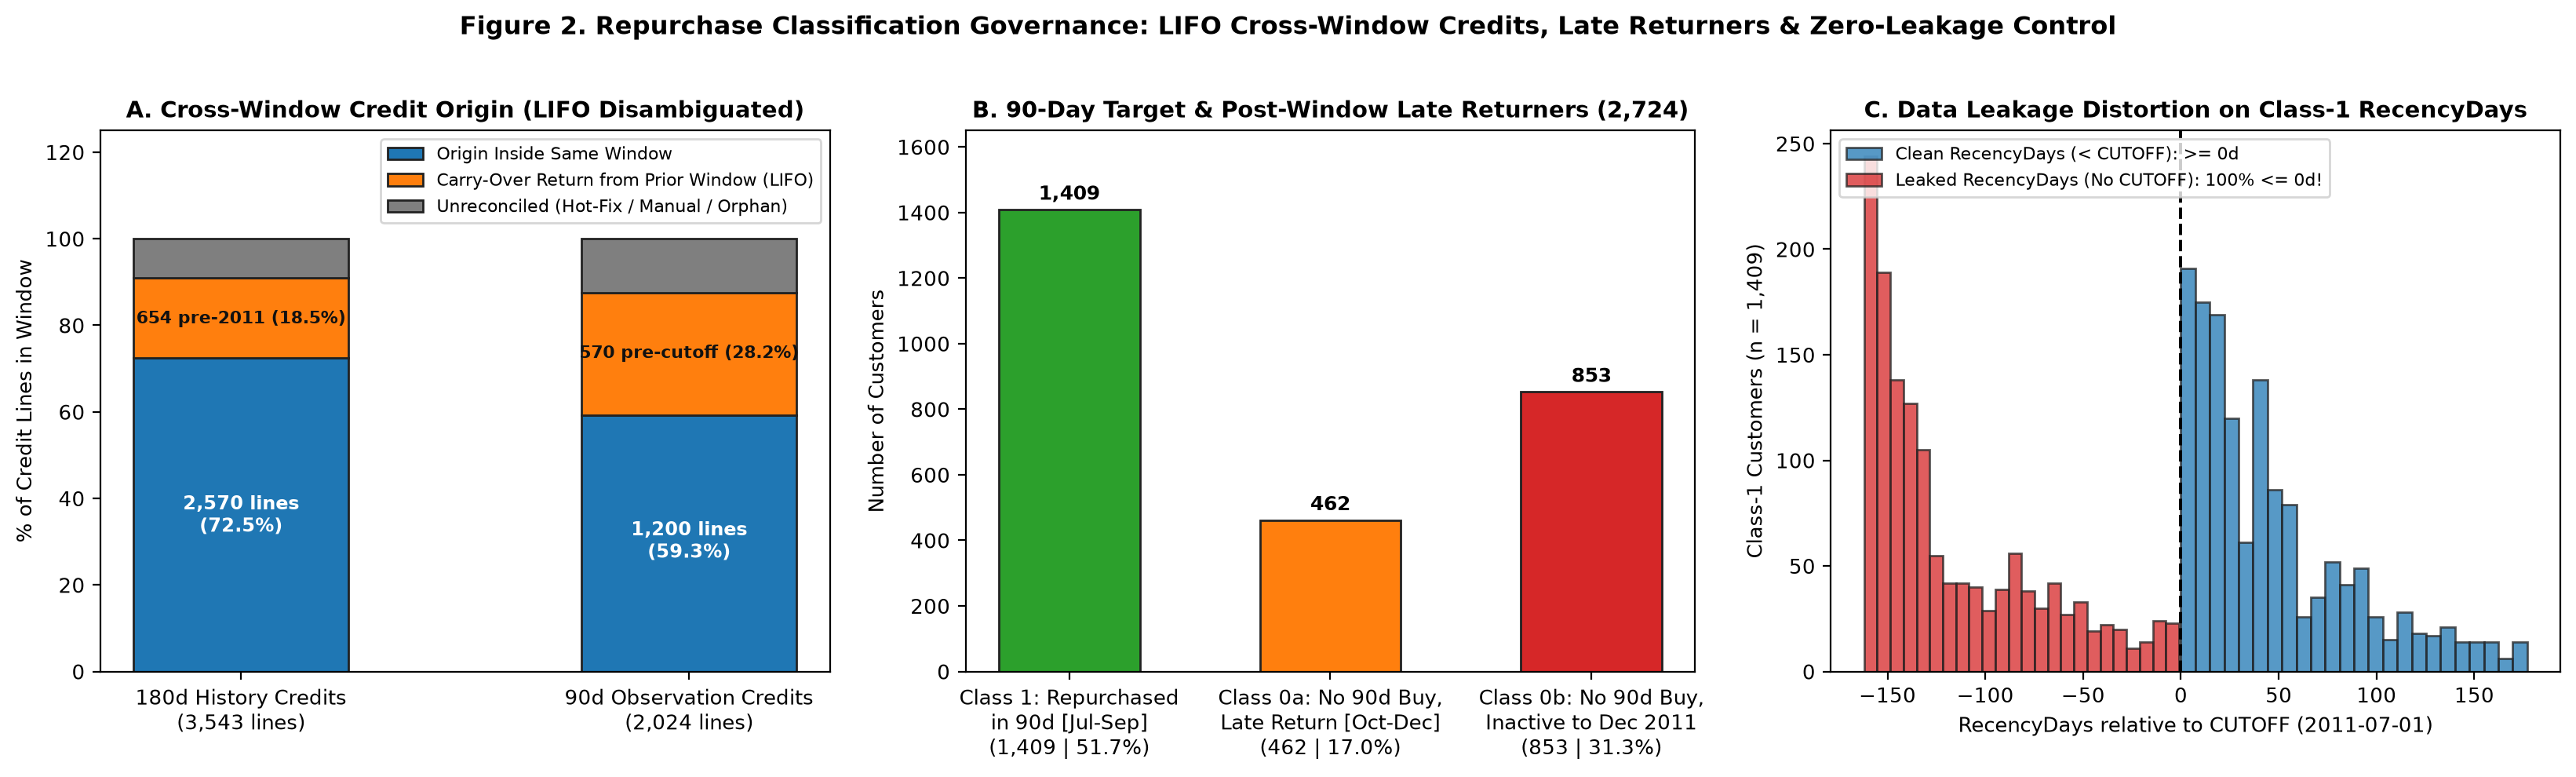

In [14]:
# Figure 2: Visual Evidence of Cross-Window LIFO Credit Traceability, Class 0 Late Returners & Data Leakage
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16.5, 4.8), dpi=200)

# Panel A: LIFO Origin of Credits in 180d History (3,543) & 90d Observation (2,024)
win_names = ['180d History Credits\n(3,543 lines)', '90d Observation Credits\n(2,024 lines)']
in_same = [72.54, 59.29]
in_prior = [18.46, 28.16]
unrec_p = [9.00, 12.55]
x_w = np.arange(len(win_names))
b1 = ax1.bar(x_w, in_same, width=0.48, label='Origin Inside Same Window', color='#1f77b4', edgecolor='#222222')
b2 = ax1.bar(x_w, in_prior, bottom=in_same, width=0.48, label='Carry-Over Return from Prior Window (LIFO)', color='#ff7f0e', edgecolor='#222222')
b3 = ax1.bar(x_w, unrec_p, bottom=np.array(in_same)+np.array(in_prior), width=0.48, label='Unreconciled (Hot-Fix / Manual / Orphan)', color='#7f7f7f', edgecolor='#222222')
ax1.set_title('A. Cross-Window Credit Origin (LIFO Disambiguated)', fontweight='bold')
ax1.set_xticks(x_w); ax1.set_xticklabels(win_names)
ax1.set_ylabel('% of Credit Lines in Window')
ax1.set_ylim(0, 125)
ax1.legend(loc='upper right', fontsize=8, frameon=True)
ax1.text(0, 36, '2,570 lines\n(72.5%)', ha='center', va='center', color='white', fontweight='bold', fontsize=8.5)
ax1.text(0, 81.5, '654 pre-2011 (18.5%)', ha='center', va='center', color='#111111', fontweight='bold', fontsize=8)
ax1.text(1, 30, '1,200 lines\n(59.3%)', ha='center', va='center', color='white', fontweight='bold', fontsize=8.5)
ax1.text(1, 73.5, '570 pre-cutoff (28.2%)', ha='center', va='center', color='#111111', fontweight='bold', fontsize=8)

# Panel B: Target Distribution (2,724) & Post-90d Late Returner Decomposition of Class 0
c_labels = ['Class 1: Repurchased\nin 90d [Jul-Sep]\n(1,409 | 51.7%)',
            'Class 0a: No 90d Buy,\nLate Return [Oct-Dec]\n(462 | 17.0%)',
            'Class 0b: No 90d Buy,\nInactive to Dec 2011\n(853 | 31.3%)']
c_vals = [1409, 462, 853]
c_colors = ['#2ca02c', '#ff7f0e', '#d62728']
bars_c = ax2.bar(c_labels, c_vals, color=c_colors, edgecolor='#222222', width=0.54)
ax2.set_title('B. 90-Day Target & Post-Window Late Returners (2,724)', fontweight='bold')
ax2.set_ylabel('Number of Customers')
ax2.set_ylim(0, 1650)
for b in bars_c:
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2, h + 30, f'{int(h):,}', ha='center', fontsize=9, fontweight='bold')

# Panel C: Data Leakage Simulation — True RecencyDays vs Leaked RecencyDays for Class 1 (1,409 customers)
true_r_c1 = cls.loc[cls['Repurchase90Days'] == 1, 'RecencyDays']
leak_r_c1 = leak_rec.loc[cls['Repurchase90Days'] == 1]
ax3.hist(true_r_c1, bins=24, alpha=0.75, color='#1f77b4', edgecolor='#222222', label='Clean RecencyDays (< CUTOFF): >= 0d')
ax3.hist(leak_r_c1, bins=24, alpha=0.75, color='#d62728', edgecolor='#222222', label='Leaked RecencyDays (No CUTOFF): 100% <= 0d!')
ax3.axvline(0, color='black', linestyle='--', linewidth=1.4)
ax3.set_title('C. Data Leakage Distortion on Class-1 RecencyDays', fontweight='bold')
ax3.set_xlabel('RecencyDays relative to CUTOFF (2011-07-01)')
ax3.set_ylabel('Class-1 Customers (n = 1,409)')
ax3.legend(loc='upper left', fontsize=8, frameon=True)

fig.suptitle('Figure 2. Repurchase Classification Governance: LIFO Cross-Window Credits, Late Returners & Zero-Leakage Control', fontsize=11.5, fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(FIG / 'fig2_classification_windows_lifo_leakage.png', bbox_inches='tight')
plt.show()

---
## 3. Cross-Dataset Reconciliation, Marketing Attribution Proxies & Export Summary
We reconcile the customer universes between `clientes_rfm.csv` (`5,878` customers) and `clientes_clasificacion.csv` (`2,724` customers), and visualize the predictive and commercial power of the marketing attribution proxy variables (`CohortMonth`, `IsUK`, `DOTCOM_OrderFlag`, `DISCOUNT_UserFlag`) and forensic basket governance rules across both datasets.

In [15]:
rfm_ids = set(rfm.index)
cls_ids = set(cls.index)
only_rfm = rfm_ids - cls_ids

first_p = purch.groupby('CustomerID')['InvoiceDate'].min()
last_p  = purch.groupby('CustomerID')['InvoiceDate'].max()

before_h = int((last_p.loc[list(only_rfm)] < H_START).sum())
after_c  = int((first_p.loc[list(only_rfm)] >= CUTOFF).sum())
gap_mid  = int(len(only_rfm) - before_h - after_c)   # bought before H_START and again >= CUTOFF, but not in [H_START, CUTOFF)

comp = pd.DataFrame([
    ('clientes_rfm.csv', len(rfm_out), '1 row per CustomerID with >=1 purchase in the full dataset',
     f'{df.InvoiceDate.min().date()} .. {df.InvoiceDate.max().date()} (REF 2011-12-10)',
     'None (unsupervised RFM segmentation + forensic & marketing proxies)',
     ', '.join(RFM_EXPORT_COLS)),
    ('clientes_clasificacion.csv', len(cls_out), '1 row per CustomerID with >=1 purchase in the 180d historical window',
     f'X: {H_START.date()} .. {CUTOFF.date()} (180d) | y: {CUTOFF.date()} .. {O_END.date()} (90d)',
     'Repurchase90Days in {0, 1} (>=1 purchase in 90d window)',
     ', '.join(CLS_EXPORT_COLS)),
], columns=['Dataset', 'Rows', 'Unit of analysis', 'Time window', 'Target variable', 'Columns'])
display(comp)

print(f'Customers in RFM: {len(rfm_ids):,} | in classification: {len(cls_ids):,} | intersection: {len(rfm_ids & cls_ids):,}')
print(f'In RFM only ({len(only_rfm):,}): last purchase < {H_START.date()}: {before_h:,} | first purchase >= {CUTOFF.date()}: {after_c:,} | inactive only during [H_START, CUTOFF): {gap_mid:,}')

# Wholesale Discount Proxy (DISCOUNT_UserFlag) vs Standard Accounts in RFM (5,878)
disc_rfm_tbl = rfm.groupby('DISCOUNT_UserFlag').agg(
    Customers=('Monetary', 'count'),
    Mean_Recency=('Recency', 'mean'),
    Median_Recency=('Recency', 'median'),
    Mean_Frequency=('Frequency', 'mean'),
    Mean_Freq_NetHotFix=('Frequency_NetHotFix', 'mean'),
    Mean_Monetary_GBP=('Monetary', 'mean'),
    Median_Monetary_GBP=('Monetary', 'median'),
    Mean_Merch_Monetary_GBP=('Monetary_Merchandise', 'mean'),
    Mean_UniqueSKUs=('UniqueSKUs', 'mean'),
    Mean_RawCreditRate_pct=('RawCreditRate', lambda s: s.mean()*100),
    Mean_TrueReturnRate_pct=('TrueReturnRate', lambda s: s.mean()*100)
)
print('\nWholesale Discount Proxy (DISCOUNT_UserFlag == 1, n = 55) vs. Standard Accounts in RFM:')
display(disc_rfm_tbl)

R['comparacion'] = dict(
    en_rfm=len(rfm_ids), en_cls=len(cls_ids), en_ambos=len(rfm_ids & cls_ids),
    solo_en_rfm=len(only_rfm), solo_rfm_ultima_antes_h=before_h,
    solo_rfm_primera_despues_corte=after_c, solo_rfm_hueco_en_h=gap_mid,
)

with open(OUT / 'resultados_actividad3.json', 'w', encoding='utf-8') as f:
    json.dump(R, f, ensure_ascii=False, indent=2, default=lambda o: int(o) if isinstance(o, np.integer) else (float(o) if isinstance(o, np.floating) else str(o)))
print('Exported outputs/resultados_actividad3.json')

Customers in RFM: 5,878 | in classification: 2,724 | intersection: 2,724
In RFM only (3,154): last purchase < 2011-01-02: 1,659 | first purchase >= 2011-07-01: 837 | inactive only during [H_START, CUTOFF): 658

Wholesale Discount Proxy (DISCOUNT_UserFlag == 1, n = 55) vs. Standard Accounts in RFM:
Exported outputs/resultados_actividad3.json


,Dataset,Rows,Unit of analysis,Time window,Target variable,Columns
0,clientes_rfm.csv,5878,1 row per CustomerID with >=1 purchase in the full dataset,2009-12-01 .. 2011-12-09 (REF 2011-12-10),None (unsupervised RFM segmentation + forensic & marketing proxies),"CustomerID, Recency, Frequency, Monetary, Frequency_NetHotFix, Monetary_Merchandise, RawCreditRate, TrueReturnRate, HotFix_Flag, UniqueSKUs, PurchaseLines_Collapsed, CohortMonth, TenureDays, Country, IsUK, DOTCOM_OrderFlag, DISCOUNT_UserFlag"
1,clientes_clasificacion.csv,2724,1 row per CustomerID with >=1 purchase in the 180d historical window,X: 2011-01-02 .. 2011-07-01 (180d) | y: 2011-07-01 .. 2011-09-29 (90d),"Repurchase90Days in {0, 1} (>=1 purchase in 90d window)","CustomerID, RecencyDays, TotalOrders, TotalSpent, Repurchase90Days, TotalOrders_NetHotFix, TotalSpent_Merchandise, TotalSpent_InWindowNet, RawCreditRate, TrueReturnRate, HotFix_Flag, UniqueSKUs, CohortMonth, TenureDays, Country, IsUK, DOTCOM_OrderFlag, DISCOUNT_UserFlag"


,Customers,Mean_Recency,Median_Recency,Mean_Frequency,Mean_Freq_NetHotFix,Mean_Monetary_GBP,Median_Monetary_GBP,Mean_Merch_Monetary_GBP,Mean_UniqueSKUs,Mean_RawCreditRate_pct,Mean_TrueReturnRate_pct
DISCOUNT_UserFlag,,,,,,,,,,,
0,5823,202.08,98.00,5.87,5.78,"2,288.55",826.96,"2,286.10",79.59,3.21,2.73
1,55,72.93,17.00,50.60,48.96,"54,996.77","15,036.14","55,419.73",318.62,8.63,7.58


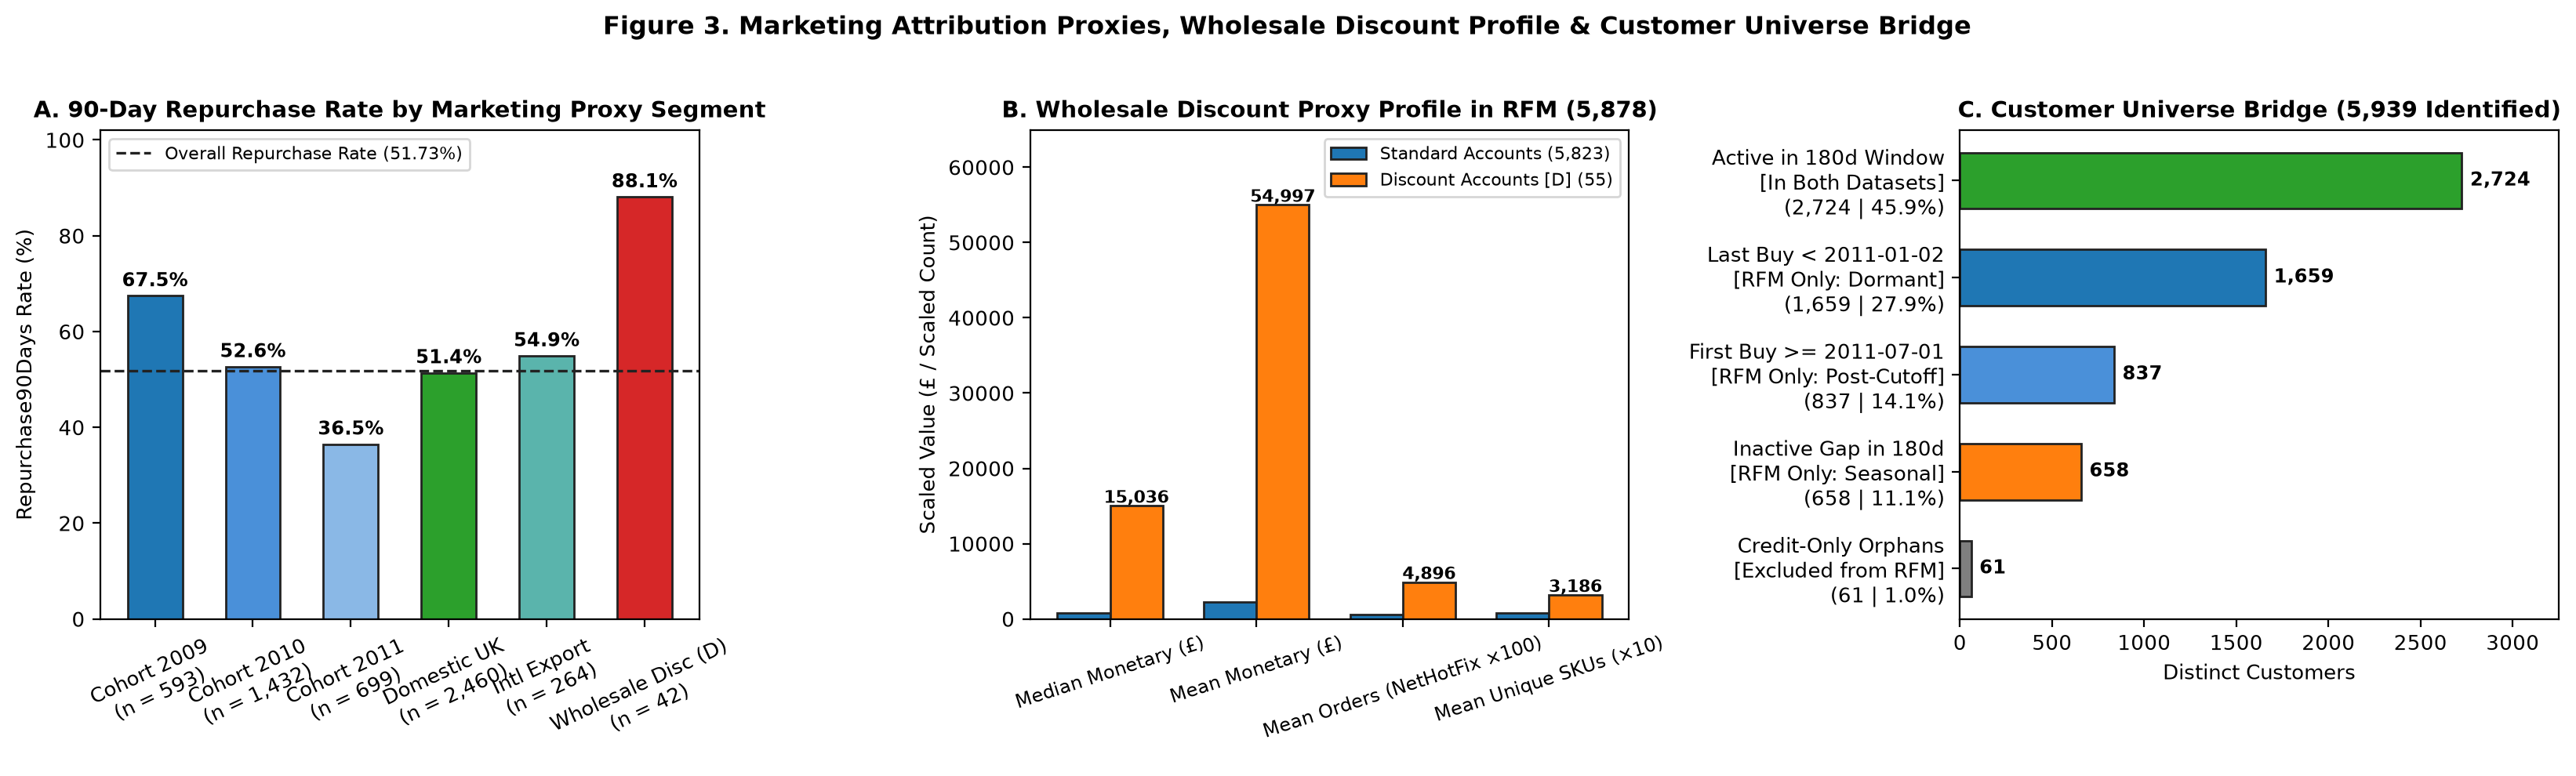

In [16]:
# Figure 3: Marketing Attribution Proxies (Cohort Retention, Wholesale Discount, UK vs Export) & Population Bridge
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16.5, 4.8), dpi=200)

# Panel A: 90-Day Repurchase Rate by Acquisition Cohort Year & Marketing Channel Proxy
seg_labels = ['Cohort 2009\n(n = 593)', 'Cohort 2010\n(n = 1,432)', 'Cohort 2011\n(n = 699)',
              'Domestic UK\n(n = 2,460)', 'Intl Export\n(n = 264)', 'Wholesale Disc (D)\n(n = 42)']
seg_rates = [67.45, 52.65, 36.48, 51.38, 54.92, 88.10]
seg_cols = ['#1f77b4', '#4a90d9', '#8ab8e6', '#2ca02c', '#5ab4ac', '#d62728']
bars_s = ax1.bar(seg_labels, seg_rates, color=seg_cols, edgecolor='#222222', width=0.56)
ax1.axhline(51.73, color='#222222', linestyle='--', linewidth=1.2, label='Overall Repurchase Rate (51.73%)')
ax1.set_title('A. 90-Day Repurchase Rate by Marketing Proxy Segment', fontweight='bold')
ax1.set_ylabel('Repurchase90Days Rate (%)')
ax1.set_ylim(0, 102)
ax1.tick_params(axis='x', rotation=25)
ax1.legend(loc='upper left', fontsize=8, frameon=True)
for b in bars_s:
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2, h + 2.0, f'{h:.1f}%', ha='center', fontsize=8.5, fontweight='bold')

# Panel B: Wholesale Discount Proxy (DISCOUNT_UserFlag == 1, n=55) vs Standard Accounts in RFM
d_cats = ['Median Monetary (£)', 'Mean Monetary (£)', 'Mean Orders (NetHotFix ×100)', 'Mean Unique SKUs (×10)']
std_vals = [rfm.loc[rfm['DISCOUNT_UserFlag']==0, 'Monetary'].median(),
            rfm.loc[rfm['DISCOUNT_UserFlag']==0, 'Monetary'].mean(),
            rfm.loc[rfm['DISCOUNT_UserFlag']==0, 'Frequency_NetHotFix'].mean()*100,
            rfm.loc[rfm['DISCOUNT_UserFlag']==0, 'UniqueSKUs'].mean()*10]
dsc_vals = [rfm.loc[rfm['DISCOUNT_UserFlag']==1, 'Monetary'].median(),
            rfm.loc[rfm['DISCOUNT_UserFlag']==1, 'Monetary'].mean(),
            rfm.loc[rfm['DISCOUNT_UserFlag']==1, 'Frequency_NetHotFix'].mean()*100,
            rfm.loc[rfm['DISCOUNT_UserFlag']==1, 'UniqueSKUs'].mean()*10]
x_d = np.arange(len(d_cats))
w_d = 0.36
bd1 = ax2.bar(x_d - w_d/2, std_vals, width=w_d, label='Standard Accounts (5,823)', color='#1f77b4', edgecolor='#222222')
bd2 = ax2.bar(x_d + w_d/2, dsc_vals, width=w_d, label='Discount Accounts [D] (55)', color='#ff7f0e', edgecolor='#222222')
ax2.set_title('B. Wholesale Discount Proxy Profile in RFM (5,878)', fontweight='bold')
ax2.set_xticks(x_d); ax2.set_xticklabels(d_cats, rotation=18, fontsize=8.5)
ax2.set_ylabel('Scaled Value (£ / Scaled Count)')
ax2.set_ylim(0, max(dsc_vals)*1.18)
ax2.legend(loc='upper right', fontsize=8, frameon=True)
for b in bd2:
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2, h + 400, f'{h:,.0f}', ha='center', fontsize=8, fontweight='bold')

# Panel C: Customer Population Bridge (5,939 Route B Identified -> 5,878 RFM -> 2,724 Classification)
bridge_cats = ['Active in 180d Window\n[In Both Datasets]\n(2,724 | 45.9%)',
               'Last Buy < 2011-01-02\n[RFM Only: Dormant]\n(1,659 | 27.9%)',
               'First Buy >= 2011-07-01\n[RFM Only: Post-Cutoff]\n(837 | 14.1%)',
               'Inactive Gap in 180d\n[RFM Only: Seasonal]\n(658 | 11.1%)',
               'Credit-Only Orphans\n[Excluded from RFM]\n(61 | 1.0%)']
bridge_vals = [2724, 1659, 837, 658, 61]
bridge_cols = ['#2ca02c', '#1f77b4', '#4a90d9', '#ff7f0e', '#7f7f7f']
b_br = ax3.barh(bridge_cats[::-1], bridge_vals[::-1], color=bridge_cols[::-1], edgecolor='#222222', height=0.58)
ax3.set_title('C. Customer Universe Bridge (5,939 Identified)', fontweight='bold')
ax3.set_xlabel('Distinct Customers')
ax3.set_xlim(0, 3250)
for b in b_br:
    w = b.get_width()
    ax3.text(w + 45, b.get_y() + b.get_height()/2, f'{int(w):,}', va='center', fontsize=8.5, fontweight='bold')

fig.suptitle('Figure 3. Marketing Attribution Proxies, Wholesale Discount Profile & Customer Universe Bridge', fontsize=11.5, fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(FIG / 'fig3_marketing_proxies_and_forensic_governance.png', bbox_inches='tight')
plt.show()